# Survival in glioblastoma: who lives longer, and can we predict it for an individual patient?

**Data:** CFB-GBM collection (The Cancer Imaging Archive), clinical, treatment, RANO and PyRadiomics tables.

**The two questions from the physician**
1. Which characteristics best predict *longer* survival?
2. Can we build a model that gives an **individualized survival prediction** from clinical characteristics, diagnosis and/or radiomic imaging features?

## Key findings (summary)
**Cohort.** 264 patients, all followed until death. Median overall survival was **50 weeks (95% CI 45–55; ≈ 11.5 months)**: 71% alive at 6 months, 48% at 1 year, 12.5% at 2 years.

**1. Best predictors of longer survival** (multivariable Cox; HR < 1 = longer survival)

| Predictor | Adjusted effect | Comment |
|---|---|---|
| **Younger age** | HR 1.20 per 10 years (1.04–1.39) | Little difference below ~65; risk rises steeply after 70 |
| **Good performance status** | PS 3 vs 0–1: HR 2.0 (1.2–3.4); PS 2: HR 1.3 | PS 2 matters mainly in the first 6 months (HR 1.9 early vs 1.0 later) |
| **Smaller tumour volume** at t0 | Threshold effect | Survival is similar up to ~40–60 cm³ and drops for large tumours (top quintile > 72 cm³: median 25 vs ~53 weeks) |
| **Conventional (60 Gy) radiotherapy** | Hypofractionated: HR 1.7 (1.2–2.4) | *Prognostic, not causal*: hypofractionation is given to older and frailer patients (confounding by indication) |
| **WHO 2016 classification** | WHO 2021: HR 1.45 (1.10–1.90) | Consistent with the 2021 reclassification of IDH-mutant (better-prognosis) tumours out of "glioblastoma" |
| **FLAIR texture** (radiomics) | 26 FLAIR features remain significant after adjusting for all of the above (FDR 5%) | More heterogeneous, higher-entropy FLAIR signal inside the tumour goes with longer survival |
| *Not predictive* | Sex, BMI, height, weight | HR ≈ 1.0 (see §7) |

By model contribution the ranking is **age ≈ tumour volume ≈ WHO edition > performance status ≈ RT regimen**.
Most "significant" T1-Gd radiomic features are **tumour size in disguise** (16 of 20 correlate |r| ≥ 0.7 with volume).

**2. Individualized prediction model**
* **Final model (Model C)** is a Cox model with age (spline), PS, WHO edition, RT regimen, tumour volume (spline) and 5 FLAIR texture components. It gives each patient a full survival curve, a predicted median, and the probability of being alive at 6, 12 and 24 months (§5.6).
* **Honest (10 × 5-fold cross-validated) performance:** C-index **0.64**; AUC 0.74 at 6 months, 0.71 at 1 year, 0.67 at 2 years. Well calibrated at 6 and 12 months, slightly optimistic at 2 years for the best-prognosis patients.
* **Radiomics on its own (C ≈ 0.61) is weaker than clinical data**, but adds a small, consistent gain on top (ΔC +0.01, mostly better 2-year discrimination). A **bedside version (Model B)** that needs only age, PS, planned RT regimen and tumour volume performs almost as well (C 0.63).
* **Cross-validated risk groups:** median survival **28 / 50 / 63 weeks**; 1-year survival **27% / 47% / 67%** (high / intermediate / low risk).
* **At the first follow-up MRI**, radiological progression roughly doubles the hazard of death (HR 2.2, 1.4–3.3) beyond the baseline factors. This is a natural "update" point for the prediction.

**3. Body size, sex and fitness (§7)**
* **BMI, height, weight and sex are not associated with survival, tumour size, performance status or early tumour shrinkage** after adjustment (all 95% CIs include 1). BMI is not a marker of fitness here (correlation with PS ≈ 0). The 14 underweight patients have a shorter median survival (32 vs 51 weeks), but the group is too small for a firm conclusion.
* **Treatment choice is driven by age, not sex or body size.** The odds of the short 3-week course rise ~9-fold per decade of age. Sex has no independent effect (OR 0.67, 0.29–1.55).
* **There is no evidence that the effect of the radiotherapy schedule depends on body size or sex** (interaction p = 0.17–0.69). Radiotherapy dose is per kg of irradiated tissue, not per kg of body weight.
* **Early "progression" on the first follow-up scan depends strongly on baseline size**: 43% of the smallest third vs 10% of the largest third. This is largely a measurement artefact of RANO's relative (+25%) threshold, not true biology.

**4. Stratified analyses (§8)**
* **The best predictors are the same across age groups and fitness levels.** FLAIR texture is the top predictor in 4 of 5 subgroups, and WHO edition is consistently in the top 3. Two possible differences need confirmation: performance status matters mainly in patients ≥ 75 (interaction p = 0.04), and the poor prognosis of hypofractionated RT is concentrated in PS 2–3 patients (p = 0.06).
* **For prediction, separate models per subgroup are worse** (too few patients each). **Stratifying Model C by age group gives a small, consistent gain** (C 0.645 vs 0.638; better in 76% of CV splits). It is a promising variant, not yet a replacement.

**Main caveat:** single centre, no MGMT/IDH/extent of resection, no external validation. Discrimination is modest, as is typical without molecular markers. The model ranks patients usefully, but individual survival times remain very uncertain: the 50% prediction interval spans about ±25 weeks.

## Glossary (for readers outside oncology and biostatistics)

**The disease and the clinical variables**

| Term | Plain-language meaning |
|---|---|
| **Glioblastoma (GBM)** | The most common and most aggressive primary brain cancer in adults. Typical survival is about a year even with treatment. |
| **WHO classification 2016 vs 2021** | Editions of the World Health Organization rulebook for naming brain tumours. Since 2021, "glioblastoma" requires the tumour to be **IDH-wildtype** (no mutation in the *IDH* gene). Tumours with the mutation, which have a better prognosis, are now called something else. Patients diagnosed under the 2016 rules may include some of these better-prognosis tumours. |
| **WHO performance status (PS)** | A 0–5 score of how well a patient copes with daily life: 0 = fully active, 1 = symptoms but walking around, 2 = in bed < 50% of the day, 3 = in bed > 50%, 4 = bedbound. It is the oncologist's standard measure of overall "fitness". |
| **BMI** | Body-mass index = weight (kg) / height (m)². < 18.5 underweight, 18.5–25 normal, 25–30 overweight, ≥ 30 obese. |
| **t0, t1, t2** | The three MRI time points: **t0** = baseline scan before radiotherapy (time zero for survival); **t1** = first follow-up scan after treatment; **t2** = second follow-up. |

**Treatment**

| Term | Plain-language meaning |
|---|---|
| **Radiotherapy (RT)** | Treatment with high-energy X-rays aimed at the tumour region. |
| **Gray (Gy)** | Unit of radiation dose = 1 joule of energy absorbed **per kilogram of irradiated tissue**. Because it is already "per kg of tissue", the dose is **not** scaled to body weight; it is prescribed to the tumour region. |
| **Fraction** | One daily treatment session. 60 Gy in 30 fractions = 2 Gy per day for 6 weeks. |
| **Conventional vs hypofractionated RT** | Conventional = 60 Gy / 30 fractions (6 weeks), the standard for fitter patients. Hypofractionated = 40.05 Gy / 15 fractions (3 weeks): fewer, larger doses, used for older or frailer patients to shorten treatment. |
| **EQD2** | Converts different schedules to a common "equivalent dose in 2 Gy fractions". 40.05 Gy/15 ≈ 42 Gy EQD2 vs 60 Gy for the standard course, so "dose" and "regimen" carry the same information in this cohort. |

**Imaging**

| Term | Plain-language meaning |
|---|---|
| **MRI sequence** | One type of MRI picture. Each sequence highlights different tissue properties, like different camera filters. |
| **T1-Gd** | T1-weighted MRI taken **after injecting gadolinium contrast**. Contrast leaks where the tumour has broken the blood–brain barrier, so the active tumour edge lights up bright ("enhancing tumour"). Used for tumour size and RANO response. |
| **FLAIR** | *Fluid-Attenuated Inversion Recovery*: a T2-weighted sequence in which normal brain fluid (CSF) is made dark. Swelling (oedema) and infiltrating, non-enhancing tumour then stand out as bright. Its texture describes how uniform or patchy that signal is. |
| **ADC, T2\*, T2-TSE, T1-EG** | Other sequences: ADC measures how freely water moves (a proxy for how densely packed cells are), T2\* is sensitive to blood products. These are missing for many patients here, so they were not modelled. |
| **GTV** | *Gross tumour volume*: the outline of the visible tumour drawn for radiotherapy planning. All radiomic features are computed inside this outline. |
| **Radiomics / PyRadiomics** | Turning an image into numbers. Software (PyRadiomics) measures ~100 features of the tumour region: **shape** (volume, diameter, sphericity), **first-order** (brightness histogram: mean, entropy, skewness) and **texture** (GLCM, GLRLM, GLSZM, GLDM, NGTDM: how bright and dark voxels are arranged; smooth vs patchy). |
| **RANO criteria** | Standard rules for judging response on follow-up MRI: complete response (tumour gone), partial response (≥ 50% smaller), stable disease, progressive disease (≥ 25% larger or new lesions). |
| **Pseudoprogression** | Swelling caused by radiation that looks like growth on MRI in the first months but is not true progression. |

**Statistics**

| Term | Plain-language meaning |
|---|---|
| **Survival analysis** | Methods for "time until an event" (here, death). |
| **Kaplan–Meier (KM) curve** | Staircase plot of the proportion of patients still alive over time. Each step down is a death. |
| **Log-rank test** | Tests whether two or more KM curves differ more than chance would explain. |
| **Hazard** | The instantaneous risk of dying at a given moment, among those still alive. |
| **Hazard ratio (HR)** | How much higher (HR > 1) or lower (HR < 1) the death rate is in one group vs another, at any point in time. HR 2 = dying at twice the rate, i.e. **shorter** survival. HR 0.5 = half the rate, i.e. **longer** survival. HR 1 = no difference. |
| **Cox regression** | The standard model for hazard ratios. It estimates the effect of several factors at once, each **adjusted** for the others. |
| **Adjusted / multivariable** | The effect of one factor while holding the other factors in the model fixed. This separates, for example, the effect of age from that of performance status. |
| **Odds ratio (OR)** | Like the HR, but for yes/no outcomes (e.g. received hypofractionated RT: yes/no). OR > 1 = more likely. |
| **95% confidence interval (CI)** | The range of effect sizes compatible with the data. If it includes 1 (for HR/OR), the data cannot rule out "no effect". |
| **p-value** | How surprising the data would be if there were truly no effect. Small (< 0.05) = unlikely to be chance alone. It does **not** measure how large or important an effect is. |
| **FDR / q-value** | A p-value corrected for testing many features at once (here ~100 radiomic features), so we don't get false alarms by sheer number of tests. |
| **Spline** | A flexible curve that lets an effect bend, e.g. age mattering little until 65 and a lot after 70, instead of forcing a straight line. |
| **Confounding by indication** | When a treatment looks harmful because it is given to sicker patients. The patients, not the treatment, explain the difference. |
| **Immortal-time bias** | A bias that appears when a predictor can only be measured in patients who survived long enough to have it measured (e.g. a follow-up scan). |
| **C-index** | Probability that, of two patients, the model correctly says which one will live longer. 0.5 = coin flip, 1 = perfect. |
| **AUC(t)** | Same idea at a fixed time *t*: how well the model separates patients who died before *t* from those who did not. |
| **Calibration** | Whether predicted probabilities are right in absolute terms (if the model says 40% alive at 1 year, ~40% should be). |
| **Brier score** | Average squared error of the predicted probabilities. Lower is better. |
| **Cross-validation** | Repeatedly hiding a fifth of the patients, building the model on the rest, and testing on the hidden fifth. This gives an honest estimate of performance on new patients. |
| **Elastic net / LASSO** | Regression that shrinks unhelpful coefficients toward zero. Used when there are many candidate features. |
| **PCA (principal components)** | Compresses many correlated features into a few summary scores that capture most of their variation. |
| **Random survival forest** | A machine-learning model made of many decision trees. Used as a check for complex patterns a Cox model might miss. |

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

from lifelines import CoxPHFitter, CoxTimeVaryingFitter, KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test
from statsmodels.stats.multitest import multipletests
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import PowerTransformer
from sksurv.ensemble import RandomSurvivalForest
from sksurv.linear_model import CoxnetSurvivalAnalysis
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv

DATA = Path("..")                 # the four .tsv files live in the project root
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
SEED = 2026
N_REPEATS = 10                    # repeats of 5-fold cross-validation
GRID = np.arange(0, 240.5, 0.5)   # weeks at which survival curves are evaluated

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

# Chart style: fixed categorical order, recessive axes, 2px lines
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
ORD = ["#6da7ec", "#2a78d6", "#104281"]   # one-hue ordinal ramp for ordered groups: darker = worse
INK, INK2, MUTED, GRIDC, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9,
    "font.family": "sans-serif", "figure.dpi": 110,
})

def savefig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=160, bbox_inches="tight")

## 1. Data assembly

| File | Content | Rows |
|---|---|---|
| clinical | survival (weeks from t0 MRI to death), age, WHO performance status (PS), sex, height, weight, WHO classification edition | 264 patients |
| treatment | radiotherapy delay, dose, number of fractions | 264 (70 with no treatment information) |
| RANO | tumour volume at t0/t1/t2 and RANO response category | 165 patients |
| PyRadiomics | 107 features per scan (shape, first-order intensity, 5 texture families) for 7 MRI sequences at t0/t1/t2 | 2,424 scans, 261 patients |

**Design decisions**
* **Time zero is the t0 MRI.** The survival column is measured from that scan, so a prediction model must use only information available at t0.
* **Every patient has an observed death time**: there is no censoring indicator and no missing survival. This is a complete-follow-up cohort (event = 1 for all). That simplifies validation, because calibration can be checked against observed proportions directly.
* **Radiotherapy regimen** is defined by dose per fraction, which reflects the *intended* schedule: conventional (1.8–2 Gy/fraction, e.g. 60 Gy/30 fx) vs hypofractionated (>2.5 Gy/fraction, e.g. 40.05 Gy/15 fx). Patients without treatment records form an explicit "Unknown" category instead of being dropped, so no one is excluded.
* **Tumour volume** comes from the t0 GTV shape features. It matches the RANO `size_t0` almost perfectly (r > 0.9999) and is available for 261 vs 165 patients.

In [2]:
clin = pd.read_csv(DATA / "CFB-GBM_clinical_data_v03_20260619.tsv", sep="\t")
trt = pd.read_csv(DATA / "CFB-GBM_treatment_data_v02_20260129.tsv", sep="\t")
rano = pd.read_csv(DATA / "CFB-GBM_rano_criteria_v04_20260909.tsv", sep="\t")
rad = pd.read_csv(DATA / "CFB_GBM_features_extraction_pyradiomics_v03_20260619.tsv", sep="\t", low_memory=False)

df = (clin.merge(trt, on="id_patient", how="left")
          .merge(rano, on="id_patient", how="left")
          .rename(columns={"survival (weeks)": "time", "age_at_t0 (years)": "age",
                           "who_performance_status": "ps", "height (cm)": "height",
                           "weight (kg)": "weight", "delay_t0_to_radiotherapy (weeks)": "rt_delay",
                           "dose (Gy)": "dose", "fractions_number": "fx"})
          .set_index("id_patient"))
df["event"] = 1
df["male"] = (df.gender == "M").astype(int)
df["bmi"] = df.weight / (df.height / 100) ** 2
df["who2021"] = (df.who_guideline == 2021).astype(int)
df["ps_missing"] = df.ps.isna()
df["ps"] = df.ps.fillna(df.ps.mode()[0])          # 1 patient; imputed with the mode (PS 1)
df["ps_cat"] = df.ps.map({0: "0-1", 1: "0-1", 2: "2", 3: "3"})
dose_per_fx = df.dose / df.fx
df["regimen"] = np.select([df.dose.isna(), dose_per_fx > 2.5], ["Unknown", "Hypofractionated"], "Conventional")

FEATS = [c for c in rad.columns if c.startswith("original_")]
SHAPE = [c for c in FEATS if "_shape_" in c]
NONSHAPE = [c for c in FEATS if "_shape_" not in c]
t0 = rad[rad.Temporality == "t0"]
t1gd = t0[t0.Sequence == "t1gd"].set_index("Patient")[FEATS]
flair = t0[t0.Sequence == "flair"].set_index("Patient")[NONSHAPE]
df["vol"] = t1gd.original_shape_MeshVolume.reindex(df.index) / 1000        # cm^3
df["log2vol"] = np.log2(df.vol)

df["age10"] = (df.age - 65) / 10
df["ps2"] = (df.ps == 2).astype(int); df["ps3"] = (df.ps == 3).astype(int)
df["hypo"] = (df.regimen == "Hypofractionated").astype(int); df["unk"] = (df.regimen == "Unknown").astype(int)
df["lv"] = df.log2vol - np.log2(30)   # centred at 30 cm^3

print(f"Patients: {len(df)} | deaths observed: {df.event.sum()} | with t0 T1-Gd radiomics: {df.vol.notna().sum()} "
      f"| with t0 FLAIR radiomics: {df.index.isin(flair.index).sum()} | with RANO: {df['size_t0 (cm3)'].notna().sum()}")
print("Check: shape features identical across sequences of the same scan ->",
      bool((t0.groupby("Patient")[SHAPE].nunique() <= 1).all().all()))
print("Check: radiomic volume vs RANO size_t0, r =",
      round(np.corrcoef(df.dropna(subset=["vol", "size_t0 (cm3)"])[["vol", "size_t0 (cm3)"]].T)[0, 1], 6))

Patients: 264 | deaths observed: 264 | with t0 T1-Gd radiomics: 261 | with t0 FLAIR radiomics: 255 | with RANO: 165
Check: shape features identical across sequences of the same scan -> True
Check: radiomic volume vs RANO size_t0, r = 0.999995


### Radiomic data available at baseline (t0)
T1-Gd (contrast-enhanced T1) and FLAIR are available for almost everyone at t0. The other sequences have substantial gaps, so they are not used for modelling.
The features were extracted from images that had already been intensity-standardized (image-wide mean ≈ 0), with 1 mm isotropic resampling and bin width 5. Intensity and texture values are therefore broadly comparable across patients.

In [3]:
avail = pd.crosstab(rad.Sequence, rad.Temporality).loc[["t1gd", "flair", "t2star", "t1eg", "adc", "t2tse", "t1tse"]]
avail.index = ["T1-Gd", "FLAIR", "T2*", "T1-EG", "ADC", "T2-TSE", "T1-TSE"]
display(avail.rename_axis("Sequence \\ timepoint"))

Temporality,t0,t1,t2
Sequence \ timepoint,,,
T1-Gd,261,159,112
FLAIR,255,159,112
T2*,238,125,88
T1-EG,212,115,76
ADC,126,122,85
T2-TSE,122,15,11
T1-TSE,0,17,14


## 2. Cohort description

In [4]:
def iqr(s):
    return f"{s.median():.0f} [{s.quantile(.25):.0f}–{s.quantile(.75):.0f}]"

def npct(mask):
    return f"{mask.sum()} ({100 * mask.mean():.0f}%)"

df["long"] = df.time >= 52
groups = {"All patients": df, "Died < 1 year": df[~df.long], "Survived ≥ 1 year": df[df.long]}
rows = {
    "N": lambda g: f"{len(g)}",
    "Survival, weeks": lambda g: iqr(g.time),
    "Age, years": lambda g: iqr(g.age),
    "Male sex": lambda g: npct(g.male == 1),
    "WHO PS 0–1": lambda g: npct(g.ps <= 1),
    "WHO PS 2": lambda g: npct(g.ps == 2),
    "WHO PS 3": lambda g: npct(g.ps == 3),
    "BMI, kg/m²": lambda g: iqr(g.bmi),
    "WHO 2021 classification": lambda g: npct(g.who2021 == 1),
    "RT conventional": lambda g: npct(g.regimen == "Conventional"),
    "RT hypofractionated": lambda g: npct(g.regimen == "Hypofractionated"),
    "RT unknown": lambda g: npct(g.regimen == "Unknown"),
    "Tumour volume, cm³": lambda g: iqr(g.vol.dropna()),
}
t1 = pd.DataFrame({k: {r: f(g) for r, f in rows.items()} for k, g in groups.items()})
a, b = df[~df.long], df[df.long]
p = {
    "Age, years": stats.mannwhitneyu(a.age, b.age).pvalue,
    "Male sex": stats.chi2_contingency(pd.crosstab(df.long, df.male))[1],
    "WHO PS 0–1": stats.chi2_contingency(pd.crosstab(df.long, df.ps_cat))[1],
    "BMI, kg/m²": stats.mannwhitneyu(a.bmi, b.bmi).pvalue,
    "WHO 2021 classification": stats.chi2_contingency(pd.crosstab(df.long, df.who2021))[1],
    "RT conventional": stats.chi2_contingency(pd.crosstab(df.long, df.regimen))[1],
    "Tumour volume, cm³": stats.mannwhitneyu(a.vol.dropna(), b.vol.dropna()).pvalue,
}
t1["p"] = pd.Series(p).map(lambda x: f"{x:.3f}" if x >= 0.001 else "<0.001")
t1["p"] = t1["p"].fillna("")
t1.to_csv(OUT / "table1.csv")
display(t1)

,All patients,Died < 1 year,Survived ≥ 1 year,p
N,264,135,129,
"Survival, weeks",50 [23–76],24 [15–40],77 [64–108],
"Age, years",70 [60–75],70 [65–75],65 [55–70],<0.001
Male sex,158 (60%),79 (59%),79 (61%),0.745
WHO PS 0–1,178 (67%),78 (58%),100 (78%),0.003
WHO PS 2,70 (27%),46 (34%),24 (19%),
WHO PS 3,16 (6%),11 (8%),5 (4%),
"BMI, kg/m²",25 [23–28],25 [22–27],25 [23–29],0.173
WHO 2021 classification,79 (30%),47 (35%),32 (25%),0.101
RT conventional,130 (49%),50 (37%),80 (62%),<0.001


In [5]:
km = KaplanMeierFitter().fit(df.time, df.event)
ci = km.confidence_interval_survival_function_
med_ci = km.median_survival_time_
from lifelines.utils import median_survival_times
mci = median_survival_times(km.confidence_interval_)
print(f"Median overall survival: {med_ci:.0f} weeks (95% CI {mci.iloc[0, 0]:.0f}–{mci.iloc[0, 1]:.0f}) "
      f"≈ {med_ci / 4.345:.1f} months")
for t in [26, 52, 104]:
    print(f"  Alive at {t:>3} weeks ({t / 52:.1f} y): {km.predict(t):.1%}")
print(f"Missing data: performance status {int(df.ps_missing.sum())} (imputed), treatment record {int(df.dose.isna().sum())} "
      f"(kept as 'Unknown' regimen), baseline imaging {int(df.vol.isna().sum())}")

Median overall survival: 50 weeks (95% CI 45–55) ≈ 11.5 months
  Alive at  26 weeks (0.5 y): 70.8%
  Alive at  52 weeks (1.0 y): 47.7%
  Alive at 104 weeks (2.0 y): 12.5%
Missing data: performance status 1 (imputed), treatment record 70 (kept as 'Unknown' regimen), baseline imaging 3


## 3. Which factors are associated with longer survival?
### 3.1 Kaplan–Meier curves

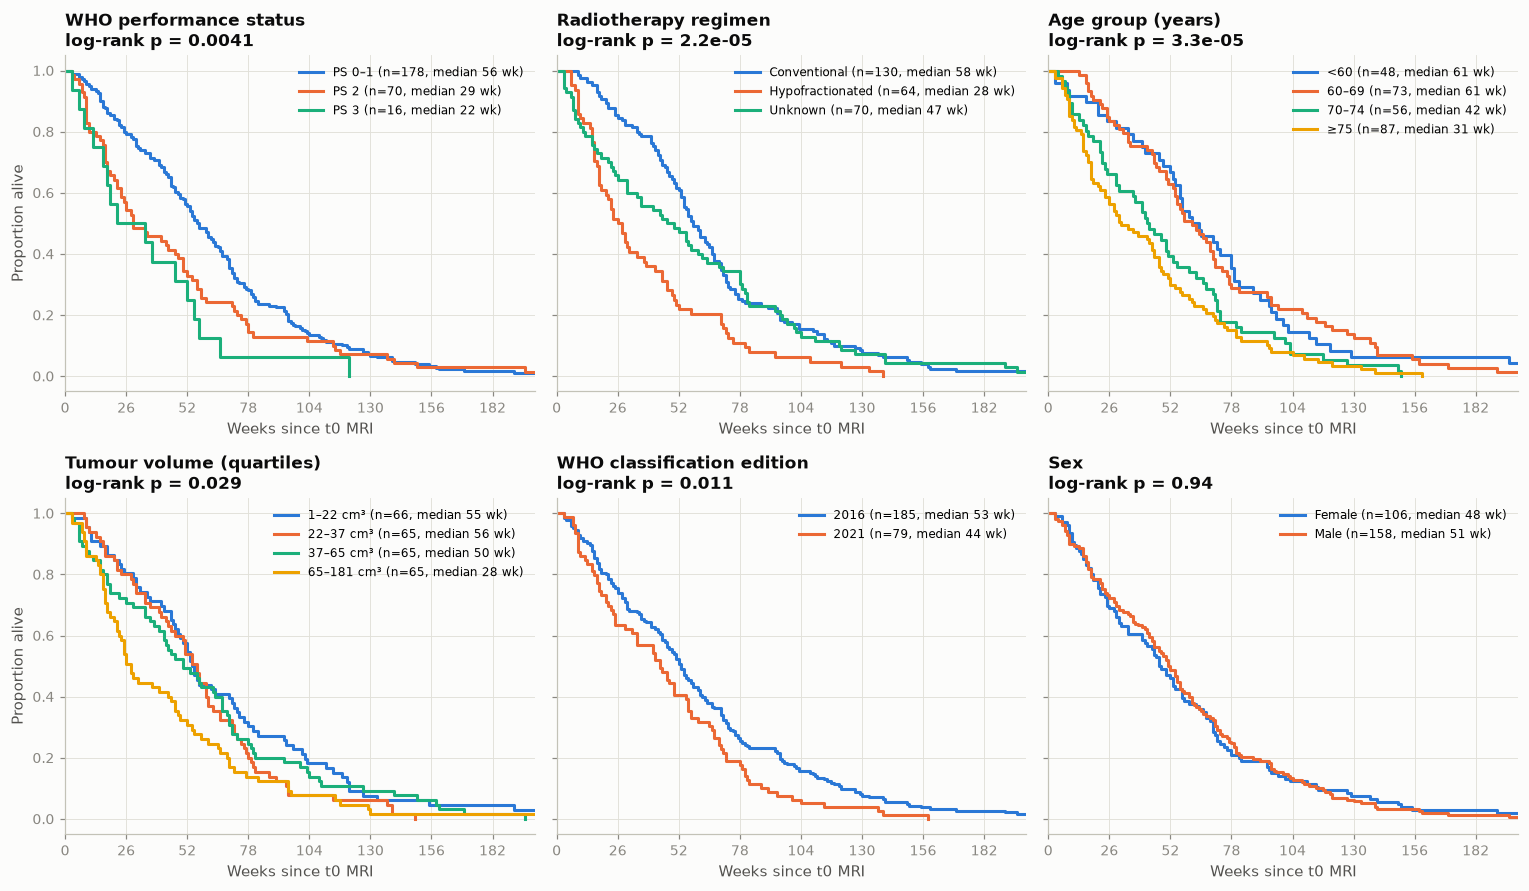

In [6]:
df["age_grp"] = pd.cut(df.age, [0, 59, 69, 74, 120], labels=["<60", "60–69", "70–74", "≥75"])
df["vol_grp"] = pd.qcut(df.vol, 4, labels=[f"Q{i}" for i in range(1, 5)])
vq = pd.qcut(df.vol, 4).cat.categories
vol_labels = {f"Q{i+1}": f"{iv.left:.0f}–{iv.right:.0f} cm³" for i, iv in enumerate(vq)}
panels = [
    ("ps_cat", "WHO performance status", {"0-1": "PS 0–1", "2": "PS 2", "3": "PS 3"}),
    ("regimen", "Radiotherapy regimen", None),
    ("age_grp", "Age group (years)", None),
    ("vol_grp", "Tumour volume (quartiles)", vol_labels),
    ("who2021", "WHO classification edition", {0: "2016", 1: "2021"}),
    ("gender", "Sex", {"F": "Female", "M": "Male"}),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 8.2), sharey=True)
logrank = {}
for ax, (var, title, labels) in zip(axes.ravel(), panels):
    sub = df.dropna(subset=[var])
    levels = [l for l in (sub[var].cat.categories if hasattr(sub[var], "cat") else sorted(sub[var].unique()))]
    if var == "regimen":
        levels = ["Conventional", "Hypofractionated", "Unknown"]
    for i, lev in enumerate(levels):
        g = sub[sub[var] == lev]
        k = KaplanMeierFitter().fit(g.time, g.event)
        lab = labels[lev] if labels else str(lev)
        k.plot_survival_function(ax=ax, ci_show=False, color=C[i], label=f"{lab} (n={len(g)}, median {k.median_survival_time_:.0f} wk)")
    pv = multivariate_logrank_test(sub.time, sub[var], sub.event).p_value
    logrank[title] = pv
    ax.set_title(f"{title}\nlog-rank p = {pv:.2g}", loc="left")
    ax.set_xlabel("Weeks since t0 MRI"); ax.set_ylabel("Proportion alive")
    ax.set_xlim(0, 200); ax.set_xticks([0, 26, 52, 78, 104, 130, 156, 182])
    ax.legend(loc="upper right", fontsize=8)
fig.tight_layout(); savefig(fig, "fig1_km_by_factor"); plt.show()

### 3.2 Univariable Cox regression
Hazard ratio (HR) > 1 means a higher death rate, i.e. **shorter** survival; HR < 1 means **longer** survival.

In [7]:
def cox_rows(cols, data, label=None):
    d = data[["time", "event"] + cols].dropna()
    s = CoxPHFitter().fit(d, "time", "event").summary
    return pd.DataFrame({"n": len(d), "HR": s["exp(coef)"], "95% CI low": s["exp(coef) lower 95%"],
                         "95% CI high": s["exp(coef) upper 95%"], "p": s["p"]})

df["bmi5"] = df.bmi / 5
uni_spec = [
    (["age10"], {"age10": "Age (per 10 years)"}),
    (["male"], {"male": "Male sex"}),
    (["bmi5"], {"bmi5": "BMI (per 5 kg/m²)"}),
    (["ps2", "ps3"], {"ps2": "WHO PS 2 (vs 0–1)", "ps3": "WHO PS 3 (vs 0–1)"}),
    (["who2021"], {"who2021": "WHO 2021 classification (vs 2016)"}),
    (["hypo", "unk"], {"hypo": "Hypofractionated RT (vs conventional)", "unk": "RT unknown (vs conventional)"}),
    (["log2vol"], {"log2vol": "Tumour volume (per doubling)"}),
    (["rt_delay"], {"rt_delay": "Delay to RT start (per week)"}),
]
uni = pd.concat([cox_rows(c, df).rename(index=lab) for c, lab in uni_spec])
uni.to_csv(OUT / "table2_univariable_cox.csv")
display(uni.style.format({"HR": "{:.2f}", "95% CI low": "{:.2f}", "95% CI high": "{:.2f}", "p": "{:.3g}"}))

,n,HR,95% CI low,95% CI high,p
covariate,,,,,
Age (per 10 years),264,1.36,1.19,1.55,4.29e-06
Male sex,264,1.01,0.79,1.29,0.946
BMI (per 5 kg/m²),264,0.98,0.85,1.12,0.749
WHO PS 2 (vs 0–1),264,1.35,1.02,1.79,0.0349
WHO PS 3 (vs 0–1),264,2.09,1.25,3.50,0.00509
WHO 2021 classification (vs 2016),264,1.42,1.08,1.85,0.0108
Hypofractionated RT (vs conventional),264,2.01,1.48,2.72,6.94e-06
RT unknown (vs conventional),264,1.11,0.83,1.49,0.487
Tumour volume (per doubling),261,1.12,1.01,1.24,0.0255


### 3.3 Multivariable Cox model
All candidate clinical predictors are entered together. Sex and BMI are dropped because they show no association, univariable or adjusted (checked below).
**Model A** uses simple linear terms, which are easy to read as HRs.
**Model B** lets age and log-volume act non-linearly through restricted cubic splines (3 knots at the 10th/50th/90th percentiles). Model B is the basis of the prediction tool.

In [8]:
def rcs(x, knots):
    """Harrell's restricted cubic spline: returns the k-2 non-linear basis columns."""
    x = np.asarray(x, float); k = np.asarray(knots, float)
    p = lambda u: np.clip(u, 0, None) ** 3
    cols = [(p(x - k[j]) - p(x - k[-2]) * (k[-1] - k[j]) / (k[-1] - k[-2])
             + p(x - k[-1]) * (k[-2] - k[j]) / (k[-1] - k[-2])) / (k[-1] - k[0]) ** 2
            for j in range(len(k) - 2)]
    return np.column_stack(cols)

class ClinicalDesign:
    """Builds the clinical design matrix; spline knots are learned from the training data only."""
    BASE = ["age10", "ps2", "ps3", "who2021", "hypo", "unk"]

    def __init__(self, volume=True, spline=True):
        self.volume, self.spline = volume, spline

    def fit(self, d):
        self.age_k = np.percentile(d.age, [10, 50, 90])
        self.lv_k = np.percentile(d.lv, [10, 50, 90])
        return self

    def transform(self, d):
        X = d[self.BASE].astype(float).copy()
        if self.spline:
            X["age_nl"] = rcs(d.age, self.age_k)[:, 0] / 10
        if self.volume:
            X["lv"] = d.lv
            if self.spline:
                X["lv_nl"] = rcs(d.lv, self.lv_k)[:, 0]
        return X

LABELS = {"age10": "Age (per 10 years)", "ps2": "WHO PS 2 (vs 0–1)", "ps3": "WHO PS 3 (vs 0–1)",
          "who2021": "WHO 2021 classification", "hypo": "Hypofractionated RT", "unk": "RT unknown",
          "lv": "Tumour volume (per doubling)", "age_nl": "Age, non-linear term", "lv_nl": "Volume, non-linear term"}

dm = df.dropna(subset=["vol"]).copy()        # 261 patients with baseline imaging
desA = ClinicalDesign(volume=True, spline=False).fit(dm)
desB = ClinicalDesign(volume=True, spline=True).fit(dm)
XA, XB = desA.transform(dm), desB.transform(dm)
coxA = CoxPHFitter().fit(XA.assign(time=dm.time, event=dm.event), "time", "event")
coxB = CoxPHFitter().fit(XB.assign(time=dm.time, event=dm.event), "time", "event")

tabA = coxA.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
tabA.columns = ["HR", "95% CI low", "95% CI high", "p"]
tabA = tabA.rename(index=LABELS)
tabA.to_csv(OUT / "table3_multivariable_cox.csv")
display(Markdown(f"**Model A (linear terms), n = {len(dm)}, apparent C-index = {coxA.concordance_index_:.3f}**"))
display(tabA.style.format({"HR": "{:.2f}", "95% CI low": "{:.2f}", "95% CI high": "{:.2f}", "p": "{:.3g}"}))

lr = 2 * (coxB.log_likelihood_ - coxA.log_likelihood_)
print(f"Model B vs A: likelihood-ratio χ² = {lr:.1f} on 2 df, p = {stats.chi2.sf(lr, 2):.3f}; "
      f"AIC {coxA.AIC_partial_:.1f} → {coxB.AIC_partial_:.1f}; apparent C {coxA.concordance_index_:.3f} → {coxB.concordance_index_:.3f}")
for v in ["age_nl", "lv_nl"]:
    print(f"  Non-linearity test, {LABELS[v]}: p = {coxB.summary.loc[v, 'p']:.3f}")

extra = CoxPHFitter().fit(XA.assign(male=dm.male, bmi5=dm.bmi5, time=dm.time, event=dm.event), "time", "event").summary
print("Adjusted for the model A covariates: male HR {:.2f} (p={:.2f}); BMI per 5 HR {:.2f} (p={:.2f})".format(
    extra.loc["male", "exp(coef)"], extra.loc["male", "p"], extra.loc["bmi5", "exp(coef)"], extra.loc["bmi5", "p"]))

**Model A (linear terms), n = 261, apparent C-index = 0.641**

,HR,95% CI low,95% CI high,p
covariate,,,,
Age (per 10 years),1.20,1.04,1.39,0.0114
WHO PS 2 (vs 0–1),1.30,0.97,1.74,0.0805
WHO PS 3 (vs 0–1),2.01,1.18,3.41,0.00966
WHO 2021 classification,1.45,1.10,1.90,0.00798
Hypofractionated RT,1.70,1.20,2.40,0.003
RT unknown,1.09,0.81,1.49,0.564
Tumour volume (per doubling),1.07,0.96,1.18,0.213


Model B vs A: likelihood-ratio χ² = 7.9 on 2 df, p = 0.019; AIC 2359.0 → 2355.1; apparent C 0.641 → 0.651
  Non-linearity test, Age, non-linear term: p = 0.200
  Non-linearity test, Volume, non-linear term: p = 0.010
Adjusted for the model A covariates: male HR 0.99 (p=0.95); BMI per 5 HR 1.01 (p=0.88)


### 3.4 How strong is each predictor? Shape of the age and tumour-volume effects
Left: the drop in model likelihood when each predictor (all its terms) is removed from Model B. This is a likelihood-ratio χ², shown minus its degrees of freedom so predictors with more terms don't get extra credit.
Middle and right: the adjusted HR across the range of age and tumour volume, with 95% pointwise CIs.

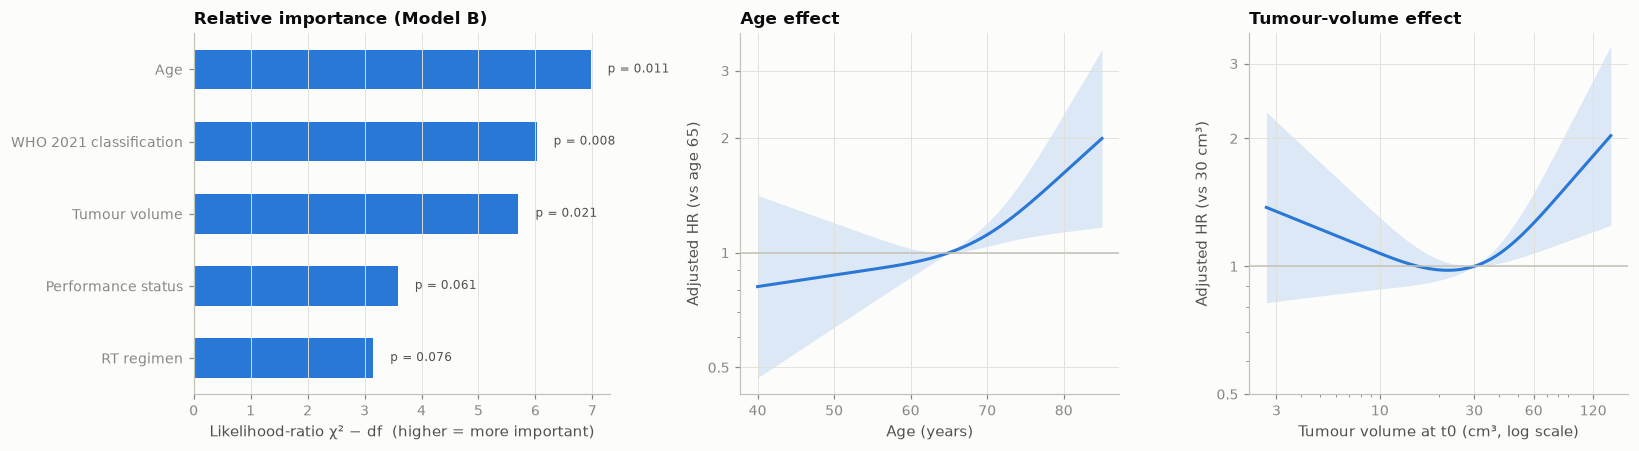

,chi2,df,p
Age,9.0,2,0.011
WHO 2021 classification,7.0,1,0.0081
Tumour volume,7.7,2,0.021
Performance status,5.6,2,0.061
RT regimen,5.2,2,0.076


In [9]:
groups_terms = {"Age": ["age10", "age_nl"], "Performance status": ["ps2", "ps3"],
                "RT regimen": ["hypo", "unk"], "WHO 2021 classification": ["who2021"],
                "Tumour volume": ["lv", "lv_nl"]}
imp = {}
for name, terms in groups_terms.items():
    red = CoxPHFitter().fit(XB.drop(columns=terms).assign(time=dm.time, event=dm.event), "time", "event")
    chi = 2 * (coxB.log_likelihood_ - red.log_likelihood_)
    imp[name] = dict(chi2=chi, df=len(terms), p=stats.chi2.sf(chi, len(terms)))
imp = pd.DataFrame(imp).T
imp["chi2 - df"] = imp.chi2 - imp.df
imp = imp.sort_values("chi2 - df")

def partial_effect(var_terms, xs, make_row, ref_row):
    """HR (with 95% CI) of each row in xs relative to the reference, from Model B."""
    beta = coxB.params_[var_terms].values
    V = coxB.variance_matrix_.loc[var_terms, var_terms].values
    D = np.array([make_row(x) for x in xs]) - np.array(make_row(ref_row))
    lp = D @ beta; se = np.sqrt(np.einsum("ij,jk,ik->i", D, V, D))
    return np.exp(lp), np.exp(lp - 1.96 * se), np.exp(lp + 1.96 * se)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1, 1]})
ax = axes[0]
ax.barh(imp.index, imp["chi2 - df"], color=C[0], height=0.55)
for i, (n, r) in enumerate(imp.iterrows()):
    ax.text(r["chi2 - df"] + 0.3, i, f"p = {r.p:.3f}" if r.p >= 0.001 else "p < 0.001", va="center", fontsize=8, color=INK2)
ax.set_xlabel("Likelihood-ratio χ² − df  (higher = more important)"); ax.set_title("Relative importance (Model B)", loc="left")
ax.grid(axis="y", visible=False)

ages = np.linspace(dm.age.quantile(.02), dm.age.quantile(.98), 100)
hr, lo, hi = partial_effect(["age10", "age_nl"], ages, lambda a: [(a - 65) / 10, rcs([a], desB.age_k)[0, 0] / 10], 65)
ax = axes[1]; ax.fill_between(ages, lo, hi, color=C[0], alpha=0.15, lw=0); ax.plot(ages, hr, color=C[0])
ax.axhline(1, color=AXIS, lw=1); ax.set_yscale("log"); ax.set_yticks([0.5, 1, 2, 3]); ax.set_yticklabels(["0.5", "1", "2", "3"])
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("Age (years)"); ax.set_ylabel("Adjusted HR (vs age 65)"); ax.set_title("Age effect", loc="left")

vols = np.exp(np.linspace(np.log(dm.vol.quantile(.02)), np.log(dm.vol.quantile(.98)), 100))
lvs = np.log2(vols) - np.log2(30)
hr, lo, hi = partial_effect(["lv", "lv_nl"], lvs, lambda v: [v, rcs([v], desB.lv_k)[0, 0]], 0.0)
ax = axes[2]; ax.fill_between(vols, lo, hi, color=C[0], alpha=0.15, lw=0); ax.plot(vols, hr, color=C[0])
ax.axhline(1, color=AXIS, lw=1); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks([3, 10, 30, 60, 120]); ax.set_xticklabels(["3", "10", "30", "60", "120"])
ax.set_yticks([0.5, 1, 2, 3]); ax.set_yticklabels(["0.5", "1", "2", "3"])
ax.yaxis.set_minor_formatter(plt.NullFormatter()); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("Tumour volume at t0 (cm³, log scale)"); ax.set_ylabel("Adjusted HR (vs 30 cm³)"); ax.set_title("Tumour-volume effect", loc="left")
fig.tight_layout(); savefig(fig, "fig2_importance_and_shapes"); plt.show()
display(imp[["chi2", "df", "p"]].iloc[::-1].style.format({"chi2": "{:.1f}", "df": "{:.0f}", "p": "{:.2g}"}))

### 3.5 Does each effect stay constant over time? (proportional-hazards check)
The Cox model assumes each HR is constant over follow-up. Schoenfeld-residual tests flag several variables, so we estimate each HR separately for the **first 6 months** (0–26 weeks) and **after 6 months**, using a time-varying-coefficient Cox model.

In [10]:
ph = proportional_hazard_test(coxA, XA.assign(time=dm.time, event=dm.event), time_transform="rank").summary
ph = ph[["test_statistic", "p"]].rename(index=LABELS)
display(Markdown("**Schoenfeld residual test (Model A)**: small p means the HR changes over time"))
display(ph.style.format({"test_statistic": "{:.2f}", "p": "{:.3f}"}))

def split_long(X, time, cut=26):
    """Episode-split each patient at `cut` weeks; returns covariates interacted with period."""
    rows = []
    for i, (idx, x) in enumerate(X.iterrows()):
        T = time.loc[idx]
        rows.append({"id": i, "start": 0, "stop": min(T, cut), "event": int(T <= cut),
                     **{f"{k}__early": v for k, v in x.items()}, **{f"{k}__late": 0.0 for k in x.index}})
        if T > cut:
            rows.append({"id": i, "start": cut, "stop": T, "event": 1,
                         **{f"{k}__early": 0.0 for k in x.index}, **{f"{k}__late": v for k, v in x.items()}})
    return pd.DataFrame(rows)

L = split_long(XA, dm.time)
ctv = CoxTimeVaryingFitter().fit(L, id_col="id", start_col="start", stop_col="stop", event_col="event")
s = ctv.summary
tv = pd.DataFrame({
    "HR 0–26 wk": s.loc[[f"{v}__early" for v in XA.columns], "exp(coef)"].values,
    "CI 0–26": [f"{a:.2f}–{b:.2f}" for a, b in s.loc[[f"{v}__early" for v in XA.columns], ["exp(coef) lower 95%", "exp(coef) upper 95%"]].values],
    "HR > 26 wk": s.loc[[f"{v}__late" for v in XA.columns], "exp(coef)"].values,
    "CI > 26": [f"{a:.2f}–{b:.2f}" for a, b in s.loc[[f"{v}__late" for v in XA.columns], ["exp(coef) lower 95%", "exp(coef) upper 95%"]].values],
}, index=[LABELS[v] for v in XA.columns])
n_late = int((dm.time > 26).sum())
display(Markdown(f"**Period-specific HRs** (all {len(dm)} patients contribute to 0–26 weeks; the {n_late} still alive at 26 weeks contribute afterwards)"))
display(tv.style.format({"HR 0–26 wk": "{:.2f}", "HR > 26 wk": "{:.2f}"}))
tv.to_csv(OUT / "table4_time_varying_hr.csv")

**Schoenfeld residual test (Model A)**: small p means the HR changes over time

,test_statistic,p
Age (per 10 years),0.00,0.945
Hypofractionated RT,3.98,0.046
Tumour volume (per doubling),1.35,0.245
WHO PS 2 (vs 0–1),6.46,0.011
WHO PS 3 (vs 0–1),0.04,0.850
RT unknown,7.16,0.007
WHO 2021 classification,0.09,0.760


**Period-specific HRs** (all 261 patients contribute to 0–26 weeks; the 184 still alive at 26 weeks contribute afterwards)

,HR 0–26 wk,CI 0–26,HR > 26 wk,CI > 26
Age (per 10 years),1.13,0.88–1.45,1.19,1.00–1.42
WHO PS 2 (vs 0–1),1.93,1.18–3.16,1.04,0.71–1.53
WHO PS 3 (vs 0–1),2.10,0.96–4.56,1.98,0.94–4.16
WHO 2021 classification,1.54,0.97–2.46,1.35,0.97–1.90
Hypofractionated RT,3.17,1.69–5.96,1.29,0.82–2.02
RT unknown,2.59,1.41–4.76,0.81,0.56–1.18
Tumour volume (per doubling),1.26,1.04–1.52,0.99,0.88–1.13


## 4. Radiomic predictors
### 4.1 Feature-by-feature screen
Each baseline feature is transformed with Yeo–Johnson to reduce skew and standardised, so HRs are **per 1 SD**.
It is then tested in a Cox model (a) on its own and (b) adjusted for age, PS, WHO edition, RT regimen and tumour volume.
p-values are corrected for testing ~100 features per sequence using the Benjamini–Hochberg false-discovery rate (q).
The colour shows how strongly each feature tracks tumour volume, because many "texture" features are just size measures in disguise.

,Features tested,"Significant, unadjusted (q<0.05)",…of which volume surrogates (|r|≥0.7),Significant after adjustment (q<0.05)
Sequence,,,,
T1-Gd,107,20,16,3
FLAIR,93,62,8,26


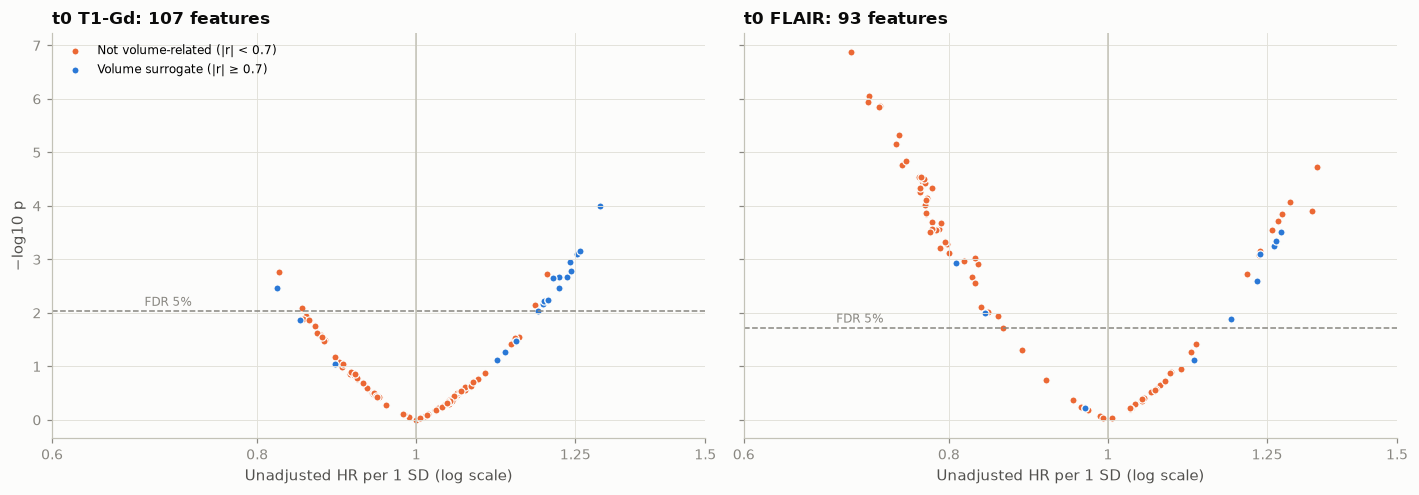

**Top FLAIR features after adjustment** (HR per 1 SD)

,HR,q,HR_adj,q_adj,r_volume
feature,,,,,
glszm_SmallAreaEmphasis,0.697,6.21e-06,0.752,0.0145,-0.427
glszm_SizeZoneNonUniformityNormalized,0.698,6.21e-06,0.752,0.0145,-0.427
glcm_Idn,1.34,0.00016,1.35,0.0145,0.649
glcm_Contrast,0.715,2.2e-05,0.791,0.0239,-0.331
glcm_DifferenceEntropy,0.725,2.2e-05,0.791,0.0239,-0.351
glcm_DifferenceAverage,0.726,2.2e-05,0.79,0.0239,-0.378
firstorder_Median,0.83,0.00177,0.831,0.0239,-0.131
glcm_DifferenceVariance,0.715,2.2e-05,0.796,0.0239,-0.272
glrlm_LongRunHighGrayLevelEmphasis,0.772,0.000198,0.812,0.0239,0.0547


**Top T1-Gd features (unadjusted)**: note the high correlation with volume

,HR,q,HR_adj,q_adj,r_volume
feature,,,,,
shape_Maximum2DDiameterSlice,1.29,0.0108,1.5,0.0229,0.822
gldm_DependenceNonUniformity,1.26,0.0234,1.75,0.0585,0.945
glszm_SizeZoneNonUniformity,1.25,0.0234,1.63,0.0585,0.936
ngtdm_Busyness,1.24,0.0234,1.27,0.277,0.86
glszm_GrayLevelNonUniformity,1.24,0.0234,1.75,0.0727,0.951
gldm_LargeDependenceHighGrayLevelEmphasis,0.825,0.0234,0.808,0.0536,0.352
shape_MajorAxisLength,1.2,0.0234,1.14,0.277,0.657
glrlm_RunLengthNonUniformity,1.23,0.0234,2.36,0.046,0.969


In [11]:
ADJ = ["age10", "ps2", "ps3", "who2021", "hypo", "unk", "lv"]

def screen(feat_df, prefix):
    ids = feat_df.index.intersection(dm.index)
    Z = pd.DataFrame(PowerTransformer().fit_transform(feat_df.loc[ids]), index=ids, columns=feat_df.columns)
    base = dm.loc[ids, ["time", "event"] + ADJ]
    out = []
    for f in Z.columns:
        u = CoxPHFitter().fit(base[["time", "event"]].assign(z=Z[f]), "time", "event").summary.loc["z"]
        a = CoxPHFitter().fit(base.assign(z=Z[f]), "time", "event").summary.loc["z"]
        out.append(dict(feature=f.replace("original_", ""), HR=u["exp(coef)"], p=u.p, HR_adj=a["exp(coef)"], p_adj=a.p,
                        r_volume=np.corrcoef(Z[f], dm.loc[ids, "lv"])[0, 1]))
    r = pd.DataFrame(out).set_index("feature")
    r["q"] = multipletests(r.p, method="fdr_bh")[1]
    r["q_adj"] = multipletests(r.p_adj, method="fdr_bh")[1]
    r["sequence"] = prefix
    return r

scr = {"T1-Gd": screen(t1gd, "T1-Gd"), "FLAIR": screen(flair, "FLAIR")}
summary_rows = []
for k, r in scr.items():
    vol_like = r.r_volume.abs() >= 0.7
    summary_rows.append({"Sequence": k, "Features tested": len(r), "Significant, unadjusted (q<0.05)": int((r.q < .05).sum()),
                         "…of which volume surrogates (|r|≥0.7)": int(((r.q < .05) & vol_like).sum()),
                         "Significant after adjustment (q<0.05)": int((r.q_adj < .05).sum())})
display(pd.DataFrame(summary_rows).set_index("Sequence"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (k, r) in zip(axes, scr.items()):
    vl = r.r_volume.abs() >= 0.7
    ax.scatter(np.log2(r.HR[~vl]), -np.log10(r.p[~vl]), s=22, color=C[1], edgecolor=SURF, linewidth=0.8, label="Not volume-related (|r| < 0.7)")
    ax.scatter(np.log2(r.HR[vl]), -np.log10(r.p[vl]), s=22, color=C[0], edgecolor=SURF, linewidth=0.8, label="Volume surrogate (|r| ≥ 0.7)")
    thr = r.p[r.q < 0.05].max() if (r.q < 0.05).any() else None
    if thr:
        ax.axhline(-np.log10(thr), color=MUTED, lw=1, ls="--"); ax.text(ax.get_xlim()[0] if False else -0.55, -np.log10(thr) + 0.1, "FDR 5%", color=MUTED, fontsize=8)
    ax.axvline(0, color=AXIS, lw=1)
    ax.set_xticks(np.log2([0.6, 0.8, 1, 1.25, 1.5])); ax.set_xticklabels(["0.6", "0.8", "1", "1.25", "1.5"])
    ax.set_xlabel("Unadjusted HR per 1 SD (log scale)"); ax.set_title(f"t0 {k}: {len(r)} features", loc="left")
axes[0].set_ylabel("−log10 p"); axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout(); savefig(fig, "fig3_radiomics_screen"); plt.show()

top_flair = scr["FLAIR"].sort_values("p_adj").head(12)[["HR", "q", "HR_adj", "q_adj", "r_volume"]]
pd.concat(scr.values()).to_csv(OUT / "table5_radiomics_screen.csv")
display(Markdown("**Top FLAIR features after adjustment** (HR per 1 SD)"))
display(top_flair.style.format("{:.3g}"))
display(Markdown("**Top T1-Gd features (unadjusted)**: note the high correlation with volume"))
display(scr["T1-Gd"].sort_values("p").head(8)[["HR", "q", "HR_adj", "q_adj", "r_volume"]].style.format("{:.3g}"))

### 4.2 FLAIR texture: one main signal behind many correlated features
The 93 FLAIR intensity and texture features are highly redundant. Principal-component analysis compresses them so we can see how many *independent* signals there are.

In [12]:
ids_f = flair.index.intersection(dm.index)
Zf = PowerTransformer().fit_transform(flair.loc[ids_f])
pca = PCA(6, random_state=SEED).fit(Zf)
PCs = pd.DataFrame(pca.transform(Zf)[:, :5], index=ids_f, columns=[f"PC{i}" for i in range(1, 6)])
PCs = PCs / PCs.std()
base = dm.loc[ids_f, ["time", "event"] + ADJ]
pc_tab = []
for pc in PCs.columns:
    a = CoxPHFitter().fit(base.assign(z=PCs[pc]), "time", "event").summary.loc["z"]
    load = pd.Series(pca.components_[int(pc[2:]) - 1], index=[c.replace("original_", "") for c in flair.columns])
    top = load.abs().sort_values(ascending=False).index[:3]
    pc_tab.append({"Component": pc, "Variance explained": pca.explained_variance_ratio_[int(pc[2:]) - 1],
                   "Adjusted HR per SD": a["exp(coef)"], "p": a.p,
                   "Top loadings": ", ".join(f"{t} ({'+' if load[t] > 0 else '−'})" for t in top)})
display(pd.DataFrame(pc_tab).set_index("Component").style.format({"Variance explained": "{:.1%}", "Adjusted HR per SD": "{:.2f}", "p": "{:.3g}"}))

,Variance explained,Adjusted HR per SD,p,Top loadings
Component,,,,
PC1,48.7%,0.83,0.0125,"gldm_SmallDependenceHighGrayLevelEmphasis (+), firstorder_Entropy (+), glcm_SumEntropy (+)"
PC2,18.5%,0.81,0.101,"firstorder_TotalEnergy (+), firstorder_Energy (+), glrlm_RunLengthNonUniformity (+)"
PC3,12.7%,1.06,0.335,"gldm_LargeDependenceLowGrayLevelEmphasis (+), glrlm_LongRunLowGrayLevelEmphasis (+), gldm_LowGrayLevelEmphasis (+)"
PC4,5.5%,1.11,0.102,"glszm_SizeZoneNonUniformity (+), gldm_DependenceNonUniformity (+), firstorder_Median (−)"
PC5,4.0%,1.19,0.014,"firstorder_Minimum (+), glcm_Correlation (+), glcm_MCC (+)"


## 5. Building an individualized survival-prediction model
### 5.1 Candidate models and how they are compared
All candidates are evaluated with **10 × repeated 5-fold cross-validation** on the 255 patients who have both T1-Gd and FLAIR at t0, so every model sees exactly the same folds.
All tuning happens **inside** the training folds: spline knots, Yeo–Johnson transforms, PCA, and the elastic-net penalty (chosen by an inner 5-fold CV).
That means the test-fold numbers are honest estimates of performance on new patients from the same population.

| Metric | Meaning | Better |
|---|---|---|
| **C-index** | Probability that, of two random patients, the one predicted to live longer actually does | higher (0.5 = coin flip) |
| **AUC(t)** | How well the predicted probability of death by week *t* separates who died by *t* from who did not | higher |
| **Integrated Brier score** | Average squared error of the predicted survival curve over 4–104 weeks; it captures both discrimination **and** calibration | lower (the no-covariate Kaplan–Meier curve is the floor to beat) |
| **Calibration at 1 year** | Mean predicted minus observed proportion alive at 52 weeks | close to 0 |

In [13]:
from joblib import Parallel, delayed

ALPHAS = np.exp(np.linspace(np.log(0.5), np.log(0.005), 25))
I26, I52, I104 = (np.searchsorted(GRID, t) for t in (26, 52, 104))

def surv_y(d):
    return Surv.from_arrays(d.event.astype(bool).values, d.time.astype(float).values)

def eval_stepfns(fns):
    return np.vstack([f(np.clip(GRID, f.x[0], f.x[-1])) for f in fns])

class KMModel:
    def fit(self, d):
        self.km = KaplanMeierFitter().fit(d.time, d.event); return self
    def survival(self, d):
        return np.tile(self.km.survival_function_at_times(GRID).values, (len(d), 1))

class CoxModel:
    """Cox PH on the clinical design, optionally plus the first k principal components of FLAIR texture.

    Only texture features that are not size surrogates (|r| with log-volume < max_vol_r in the training data)
    enter the PCA, so the components carry information *beyond* tumour volume, which is already in the model.
    """
    def __init__(self, design, flair_pcs=0, max_vol_r=0.5):
        self.design, self.k, self.max_vol_r = design, flair_pcs, max_vol_r
    def _X(self, d, fit=False):
        if fit: self.design.fit(d)
        X = self.design.transform(d)
        if self.k:   # FLAIR features come from `d` itself if present (new patients), else from the cohort table
            F = (d[flair.columns] if set(flair.columns) <= set(d.columns) else flair.loc[d.index]).values
            if fit:
                self.pt = PowerTransformer().fit(F)
                Z = self.pt.transform(F)
                r = np.array([np.corrcoef(Z[:, j], d.lv)[0, 1] for j in range(Z.shape[1])])
                self.keep = np.abs(r) < self.max_vol_r
                self.pca = PCA(self.k, random_state=SEED).fit(Z[:, self.keep])
            P = self.pca.transform(self.pt.transform(F)[:, self.keep])
            X = X.join(pd.DataFrame(P, index=d.index, columns=[f"PC{i + 1}" for i in range(self.k)]))
        return X
    def fit(self, d):
        self.cph = CoxPHFitter().fit(self._X(d, fit=True).assign(time=d.time, event=d.event), "time", "event")
        return self
    def survival(self, d):
        return self.cph.predict_survival_function(self._X(d), times=GRID).T.values

class TVCoxModel(CoxModel):
    """Cox model whose coefficients for `tv` variables change at `cut` weeks (step function)."""
    def __init__(self, design, tv=("ps2", "hypo", "unk", "lv"), cut=26):
        super().__init__(design); self.tv, self.cut = list(tv), cut
    def fit(self, d):
        X = self._X(d, fit=True); rows = []
        for i, idx in enumerate(X.index):
            x, T = X.loc[idx].to_dict(), d.time.loc[idx]
            rows.append({"id": i, "start": 0, "stop": min(T, self.cut), "event": int(T <= self.cut), **x, **{f"{v}_late": 0.0 for v in self.tv}})
            if T > self.cut:
                rows.append({"id": i, "start": self.cut, "stop": T, "event": 1, **x, **{f"{v}_late": x[v] for v in self.tv}})
        self.ctv = CoxTimeVaryingFitter().fit(pd.DataFrame(rows), id_col="id", start_col="start", stop_col="stop", event_col="event")
        H0 = self.ctv.baseline_cumulative_hazard_.iloc[:, 0]
        pos = np.searchsorted(H0.index.values, GRID, side="right") - 1
        self.H0 = np.where(pos >= 0, H0.values[np.clip(pos, 0, None)], 0.0)
        return self
    def survival(self, d):
        X = self._X(d); b = self.ctv.params_; mu = self.ctv._norm_mean[b.index]
        ev, lv = list(X.columns), [f"{v}_late" for v in self.tv]
        base = (X[ev] - mu[ev]).values @ b[ev].values
        early = np.exp(base - mu[lv].values @ b[lv].values)
        late = np.exp(base + (X[self.tv].values - mu[lv].values) @ b[lv].values)
        Hcut = np.interp(self.cut, GRID, self.H0)
        Hc, Hl = np.minimum(self.H0, Hcut), np.clip(self.H0 - Hcut, 0, None)
        return np.exp(-(early[:, None] * Hc[None, :] + late[:, None] * Hl[None, :]))

class CoxnetModel:
    """Elastic-net Cox on radiomic blocks; clinical design columns (if given) are left unpenalized."""
    def __init__(self, blocks, design=None, l1_ratio=0.5, seed=0):
        self.blocks, self.design, self.l1, self.seed = blocks, design, l1_ratio, seed
    def _X(self, d, fit=False):
        R = np.hstack([b.loc[d.index].values for b in self.blocks])
        if fit: self.pt = PowerTransformer().fit(R)
        parts = [self.pt.transform(R)]
        if self.design is not None:
            if fit: self.design.fit(d)
            parts.insert(0, self.design.transform(d).values)
        return np.hstack(parts)
    def fit(self, d):
        X, y = self._X(d, fit=True), surv_y(d)
        n_rad = sum(b.shape[1] for b in self.blocks)
        pf = np.r_[np.zeros(X.shape[1] - n_rad), np.ones(n_rad)]
        base = CoxnetSurvivalAnalysis(l1_ratio=self.l1, alphas=ALPHAS, penalty_factor=pf, fit_baseline_model=True, max_iter=100000)
        score = np.zeros(len(ALPHAS))
        for itr, iva in KFold(5, shuffle=True, random_state=self.seed).split(X):
            m = clone(base).fit(X[itr], y[itr])
            for j, a in enumerate(ALPHAS):
                score[j] += concordance_index_censored(y[iva]["event"], y[iva]["time"], m.predict(X[iva], alpha=a))[0]
        self.alpha = ALPHAS[int(np.argmax(score))]
        self.est = clone(base).fit(X, y)
        coef = self.est.coef_[:, list(ALPHAS).index(self.alpha)]
        self.n_selected = int((np.abs(coef[X.shape[1] - n_rad:]) > 1e-8).sum())
        return self
    def survival(self, d):
        return eval_stepfns(self.est.predict_survival_function(self._X(d), alpha=self.alpha))

class RSFModel:
    def __init__(self, seed=0): self.seed = seed
    def _X(self, d):
        return np.hstack([ClinicalDesign(volume=True, spline=False).fit(d).transform(d).values,
                          t1gd.loc[d.index].values, flair.loc[d.index].values])
    def fit(self, d):
        self.rsf = RandomSurvivalForest(n_estimators=500, min_samples_leaf=15, max_features="sqrt",
                                        n_jobs=1, random_state=self.seed).fit(self._X(d), surv_y(d))
        return self
    def survival(self, d):
        return eval_stepfns(self.rsf.predict_survival_function(self._X(d)))

MODELS = {
    "No covariates (Kaplan–Meier)":                 lambda s: KMModel(),
    "Clinical, no volume (Cox)":                    lambda s: CoxModel(ClinicalDesign(volume=False, spline=False)),
    "Clinical + volume, linear (Cox) [Model A]":    lambda s: CoxModel(ClinicalDesign(volume=True, spline=False)),
    "Clinical + volume, splines (Cox) [Model B]":   lambda s: CoxModel(ClinicalDesign(volume=True, spline=True)),
    "Model B + time-varying effects (Cox)":         lambda s: TVCoxModel(ClinicalDesign(volume=True, spline=True)),
    "Radiomics T1-Gd only (elastic-net Cox)":       lambda s: CoxnetModel([t1gd], seed=s),
    "Radiomics FLAIR only (elastic-net Cox)":       lambda s: CoxnetModel([flair], seed=s),
    "Radiomics T1-Gd + FLAIR (elastic-net Cox)":    lambda s: CoxnetModel([t1gd, flair], seed=s),
    "Model B + FLAIR texture (elastic-net Cox)":    lambda s: CoxnetModel([flair], design=ClinicalDesign(True, True), seed=s),
    "Model B + 5 FLAIR principal components (Cox)": lambda s: CoxModel(ClinicalDesign(True, True), flair_pcs=5),
    "Random survival forest (all features)":        lambda s: RSFModel(seed=s),
}

def metrics(T, S):
    rmst = np.trapezoid(S[:, GRID <= 156], GRID[GRID <= 156], axis=1)      # restricted mean survival to 3 years
    out = {"C-index": concordance_index_censored(np.ones(len(T), bool), T.astype(float), -rmst)[0]}
    for t, i in ((26, I26), (52, I52), (104, I104)):
        lab = (T <= t).astype(int)
        out[f"AUC {t} wk"] = roc_auc_score(lab, 1 - S[:, i]) if np.ptp(S[:, i]) > 0 else 0.5
    bt = (GRID >= 4) & (GRID <= 104)
    out["Integrated Brier"] = np.trapezoid((((T[:, None] > GRID[None, bt]) * 1.0 - S[:, bt]) ** 2).mean(0), GRID[bt]) / 100
    out["Calibration 1 y"] = S[:, I52].mean() - (T > 52).mean()
    return out

def pred_median(S):
    below = S <= 0.5
    return np.where(below.any(1), GRID[np.argmax(below, axis=1)], np.nan)

cvdat = dm.loc[dm.index.intersection(flair.index)].copy()

def run_fold(r, k, tr, te):
    TR, TE = cvdat.iloc[tr], cvdat.iloc[te]
    res, oof = [], []
    for name, make in MODELS.items():
        S = make(r * 10 + k).fit(TR).survival(TE)
        res.append({"rep": r, "fold": k, "model": name, **metrics(TE.time.values, S)})
        oof.append(pd.DataFrame({"rep": r, "model": name, "id": TE.index, "S26": S[:, I26],
                                 "S52": S[:, I52], "S104": S[:, I104], "median": pred_median(S)}))
    return res, pd.concat(oof)

cache = OUT / "cv_results.csv"
if cache.exists():
    cvres = pd.read_csv(cache); oof = pd.read_csv(OUT / "cv_oof_predictions.csv")
else:
    tasks = [(r, k, tr, te) for r in range(N_REPEATS)
             for k, (tr, te) in enumerate(KFold(5, shuffle=True, random_state=SEED + r).split(cvdat))]
    out = Parallel(n_jobs=-1)(delayed(run_fold)(*t) for t in tasks)
    cvres = pd.DataFrame([row for res, _ in out for row in res]); oof = pd.concat([o for _, o in out])
    cvres.to_csv(cache, index=False); oof.to_csv(OUT / "cv_oof_predictions.csv", index=False)
print(f"n = {len(cvdat)} patients, {cvres.rep.nunique()} repeats × 5 folds = {cvres.groupby(['rep', 'fold']).ngroups} train/test splits per model")

n = 255 patients, 10 repeats × 5 folds = 50 train/test splits per model


### 5.2 Cross-validated performance

,C-index,AUC 26 wk,AUC 52 wk,AUC 104 wk,Integrated Brier,Calibration 1 y,ΔC vs Model B,% splits better than B
model,,,,,,,,
No covariates (Kaplan–Meier),0.500000,0.500000,0.500000,0.500000,0.184764,+0.000,-0.127877,0.000000
"Clinical, no volume (Cox)",0.619448,0.688995,0.697186,0.635001,0.171600,-0.005,-0.008429,32.000000
"Clinical + volume, linear (Cox) [Model A]",0.619671,0.701919,0.692887,0.634037,0.171784,-0.006,-0.008205,28.000000
"Clinical + volume, splines (Cox) [Model B]",0.627877,0.725604,0.713194,0.631896,0.170696,-0.005,0.000000,0.000000
Model B + time-varying effects (Cox),0.625833,0.741085,0.711081,0.618294,0.169340,+0.005,-0.002043,40.000000
Radiomics T1-Gd only (elastic-net Cox),0.605371,0.696464,0.664131,0.585836,0.179516,-0.016,-0.022506,24.000000
Radiomics FLAIR only (elastic-net Cox),0.612188,0.689392,0.680163,0.627055,0.176873,-0.006,-0.015688,42.000000
Radiomics T1-Gd + FLAIR (elastic-net Cox),0.612433,0.697902,0.682402,0.606268,0.179955,-0.012,-0.015443,40.000000
Model B + FLAIR texture (elastic-net Cox),0.623744,0.713589,0.694332,0.656055,0.175653,-0.009,-0.004132,52.000000


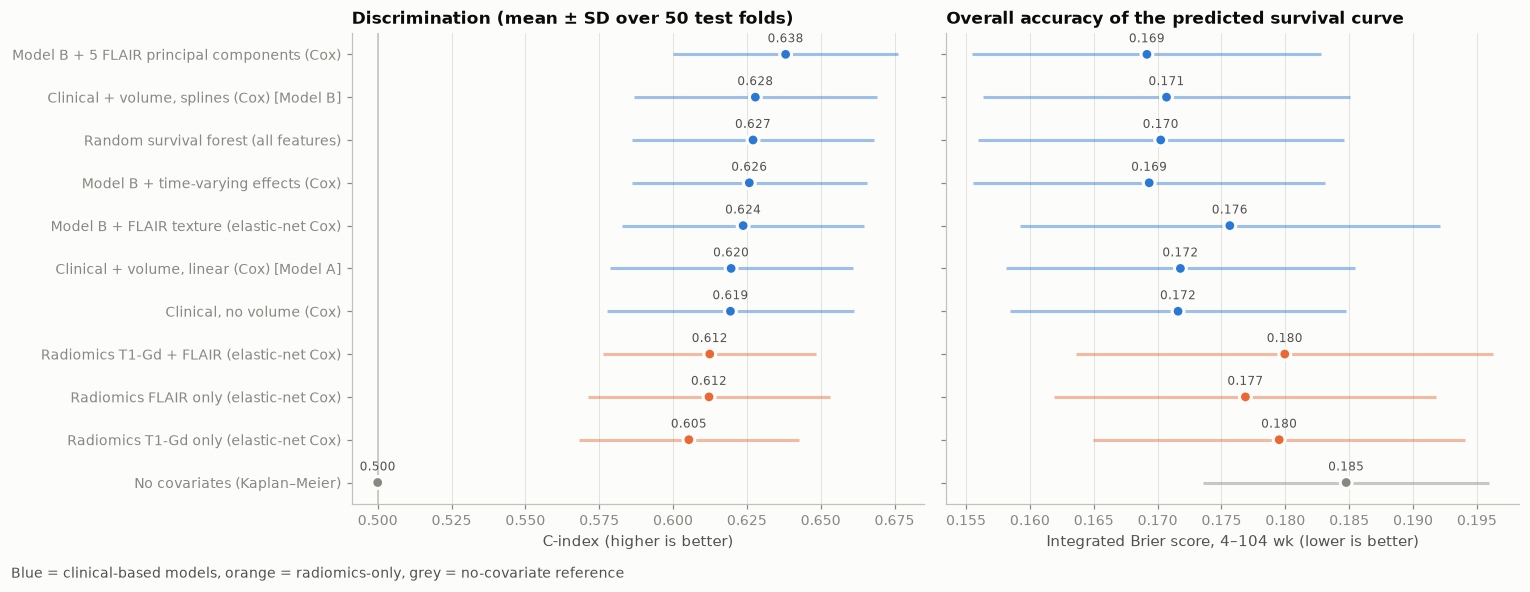

In [14]:
cols = ["C-index", "AUC 26 wk", "AUC 52 wk", "AUC 104 wk", "Integrated Brier", "Calibration 1 y"]
perf = cvres.groupby("model")[cols].mean()
perf_sd = cvres.groupby("model")[cols].std()
ref = "Clinical + volume, splines (Cox) [Model B]"
paired = cvres.pivot_table(index=["rep", "fold"], columns="model", values="C-index")
perf["ΔC vs Model B"] = (paired.sub(paired[ref], axis=0)).mean()
perf["% splits better than B"] = (paired.gt(paired[ref], axis=0)).mean() * 100
perf = perf.loc[list(MODELS)]
perf.to_csv(OUT / "table6_cv_performance.csv")
display(perf.style.format({c: "{:.3f}" for c in cols} | {"ΔC vs Model B": "{:+.3f}", "% splits better than B": "{:.0f}%"})
        .format({"Calibration 1 y": "{:+.3f}"}))

order = perf["C-index"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, metric, xlabel in [(axes[0], "C-index", "C-index (higher is better)"),
                           (axes[1], "Integrated Brier", "Integrated Brier score, 4–104 wk (lower is better)")]:
    m, sd = perf.loc[order, metric], perf_sd.loc[order, metric]
    colors = [C[1] if "Radiomics" in n and "Model B" not in n else (MUTED if "Kaplan" in n else C[0]) for n in order]
    ax.hlines(range(len(order)), m - sd, m + sd, color=colors, lw=2, alpha=0.45)
    ax.scatter(m, range(len(order)), color=colors, s=60, zorder=3, edgecolor=SURF, linewidth=2)
    for i, v in enumerate(m):
        ax.text(v, i + 0.28, f"{v:.3f}", ha="center", fontsize=8, color=INK2)
    ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels(order)
axes[0].axvline(0.5, color=AXIS, lw=1)
axes[0].set_title("Discrimination (mean ± SD over 50 test folds)", loc="left")
axes[1].set_title("Overall accuracy of the predicted survival curve", loc="left")
fig.text(0.01, -0.02, "Blue = clinical-based models, orange = radiomics-only, grey = no-covariate reference", color=INK2, fontsize=9)
fig.tight_layout(); savefig(fig, "fig4_cv_performance"); plt.show()

**Reading the comparison**
* Every model with covariates clearly beats the no-covariate reference, but discrimination is **modest** for all of them (C ≈ 0.61–0.64). That is typical for glioblastoma when the strongest known prognostic markers (MGMT promoter methylation, IDH status, extent of resection) are not available.
* **Radiomics alone underperforms the clinical model.** Most of the T1-Gd signal is tumour size, which the clinical model already captures through volume.
* **High-dimensional radiomics overfits.** Adding 93 FLAIR features through an elastic net (ΔC ≈ −0.004) does worse than compressing the volume-independent ones first into 5 principal components (ΔC ≈ +0.010, better in ~2/3 of splits). The PC version also clearly improves 2-year discrimination (AUC 0.67 vs 0.63).
* A random survival forest is no better than the Cox models, so there is no evidence of strong interactions or non-linearities that a Cox model misses.

**Final model ("Model C") = Model B + 5 FLAIR texture components.** The components are built only from the 74 FLAIR features that are *not* size surrogates (|r| with log-volume < 0.5). A first version that used all 93 features let components such as `TotalEnergy` and `SizeZoneNonUniformity` duplicate the volume term. That made the volume coefficient flip sign and produced implausible predictions for hypothetical patients. It has the best C-index and 2-year AUC, an integrated Brier score as good as any candidate, and is still a transparent Cox model.
**Model B** (clinical + volume only) is kept as the **bedside version**. It needs only age, PS, planned RT regimen and tumour volume, and loses only about 0.01 in C-index.

### 5.3 The final model

In [15]:
FINAL_NAME, BEDSIDE_NAME = "Model B + 5 FLAIR principal components (Cox)", "Clinical + volume, splines (Cox) [Model B]"
final = CoxModel(ClinicalDesign(volume=True, spline=True), flair_pcs=5).fit(cvdat)
bedside = CoxModel(ClinicalDesign(volume=True, spline=True)).fit(dm)

print(f"FLAIR features entering the PCA: {final.keep.sum()} of {len(final.keep)} "
      f"(excluded as volume surrogates: {', '.join(c.replace('original_', '') for c in flair.columns[~final.keep])})")
loads = pd.DataFrame(final.pca.components_.T, index=[c.replace("original_", "") for c in flair.columns[final.keep]],
                     columns=[f"PC{i + 1}" for i in range(5)])
pc_desc = {pc: ", ".join(f"{f} ({'+' if loads.loc[f, pc] > 0 else '−'})" for f in loads[pc].abs().sort_values(ascending=False).index[:3])
           for pc in loads.columns}
ftab = final.cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].copy()
ftab.columns = ["HR", "95% CI low", "95% CI high", "p"]
pc_sd = final._X(cvdat)[[f"PC{i + 1}" for i in range(5)]].std()
for pc in pc_sd.index:   # express PC effects per 1 SD of the component
    ftab.loc[pc, ["HR", "95% CI low", "95% CI high"]] = np.exp(np.log(ftab.loc[pc, ["HR", "95% CI low", "95% CI high"]].astype(float)) * pc_sd[pc])
ftab.index = [LABELS.get(i, f"FLAIR {i} (per SD): {pc_desc.get(i, '')}") for i in ftab.index]
ftab.to_csv(OUT / "table7_final_model.csv")
display(Markdown(f"**Model C coefficients** (n = {len(cvdat)}). The spline terms are jointly interpretable through the curves in §3.4; the FLAIR components are listed with their three largest loadings."))
display(ftab.style.format({"HR": "{:.2f}", "95% CI low": "{:.2f}", "95% CI high": "{:.2f}", "p": "{:.3g}"}))

FLAIR features entering the PCA: 74 of 93 (excluded as volume surrogates: firstorder_Energy, firstorder_TotalEnergy, glcm_Idmn, glcm_Idn, glrlm_GrayLevelNonUniformity, glrlm_RunLengthNonUniformity, glszm_GrayLevelNonUniformity, glszm_LargeAreaEmphasis, glszm_LargeAreaHighGrayLevelEmphasis, glszm_SizeZoneNonUniformity, glszm_ZonePercentage, glszm_ZoneVariance, gldm_DependenceNonUniformity, gldm_DependenceNonUniformityNormalized, gldm_GrayLevelNonUniformity, gldm_SmallDependenceLowGrayLevelEmphasis, ngtdm_Busyness, ngtdm_Coarseness, ngtdm_Strength)


**Model C coefficients** (n = 255). The spline terms are jointly interpretable through the curves in §3.4; the FLAIR components are listed with their three largest loadings.

,HR,95% CI low,95% CI high,p
Age (per 10 years),1.00,0.79,1.26,0.998
WHO PS 2 (vs 0–1),1.17,0.86,1.59,0.326
WHO PS 3 (vs 0–1),1.92,1.10,3.37,0.0225
WHO 2021 classification,1.53,1.15,2.03,0.00315
Hypofractionated RT,1.44,0.99,2.09,0.058
RT unknown,1.07,0.77,1.47,0.695
"Age, non-linear term",1.33,0.98,1.79,0.0636
Tumour volume (per doubling),0.81,0.63,1.04,0.099
"Volume, non-linear term",1.23,0.98,1.54,0.0755
"FLAIR PC1 (per SD): firstorder_Entropy (+), gldm_SmallDependenceHighGrayLevelEmphasis (+), glcm_SumEntropy (+)",0.85,0.73,0.99,0.0321


### 5.4 Calibration: do predicted survival probabilities match what actually happened?
Each patient's prediction is **out-of-fold**: it comes from models that never saw that patient, averaged over the 10 CV repeats.
Patients are grouped into fifths by predicted probability of being alive at 6, 12 and 24 months, and compared with the observed proportion alive in each group. Because nobody is censored, the observed proportion is exact.
Points on the diagonal mean perfect calibration.

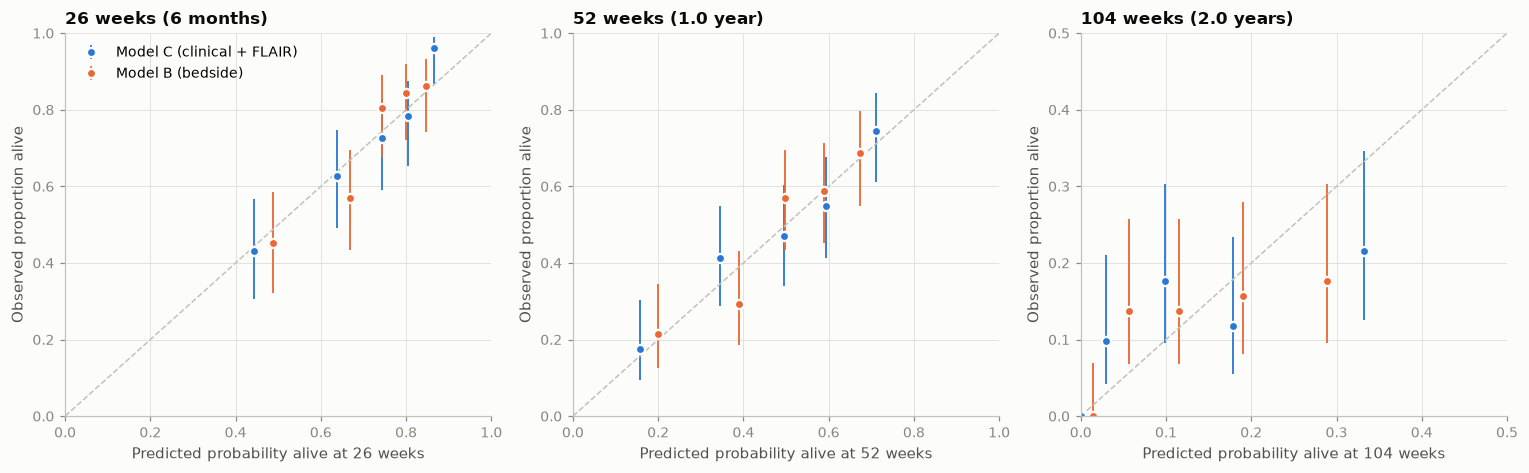

,,Mean predicted,Observed,Calibration slope
Model,Horizon,,,
Model C (clinical + FLAIR),26 wk,0.70,0.71,0.72
Model B (bedside),26 wk,0.71,0.71,0.74
Model C (clinical + FLAIR),52 wk,0.47,0.47,0.72
Model B (bedside),52 wk,0.47,0.47,0.74
Model C (clinical + FLAIR),104 wk,0.13,0.12,0.74
Model B (bedside),104 wk,0.13,0.12,0.75


In [16]:
def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h

oof_avg = {m: oof[oof.model == m].groupby("id")[["S26", "S52", "S104", "median"]].mean().join(cvdat[["time"]])
           for m in [FINAL_NAME, BEDSIDE_NAME]}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
cal_rows = []
for ax, (t, col) in zip(axes, [(26, "S26"), (52, "S52"), (104, "S104")]):
    for j, (m, lab) in enumerate([(FINAL_NAME, "Model C (clinical + FLAIR)"), (BEDSIDE_NAME, "Model B (bedside)")]):
        o = oof_avg[m]; q = pd.qcut(o[col].rank(method="first"), 5, labels=False)
        g = o.groupby(q).agg(pred=(col, "mean"), k=("time", lambda x: (x > t).sum()), n=("time", "size"))
        g["obs"] = g.k / g.n; lo, hi = wilson(g.k, g.n)
        off = (j - 0.5) * 0.008
        ax.errorbar(g.pred + off, g.obs, yerr=[g.obs - lo, hi - g.obs], fmt="o", color=C[j], ms=6, lw=1.2, capsize=0,
                    label=lab, mec=SURF, mew=1.5)
        cll = np.log(-np.log(np.clip(o[col], 1e-6, 1 - 1e-6)))
        slope = CoxPHFitter().fit(pd.DataFrame({"time": o.time, "event": 1, "cll": cll}), "time", "event").params_["cll"]
        cal_rows.append({"Model": lab, "Horizon": f"{t} wk", "Mean predicted": o[col].mean(), "Observed": (o.time > t).mean(),
                         "Calibration slope": slope})
    ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
    lim = 0.5 if t == 104 else 1.0
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel(f"Predicted probability alive at {t} weeks"); ax.set_ylabel("Observed proportion alive")
    ax.set_title(f"{t} weeks ({t / 52:.1f} year{'s' if t > 52 else ''})" if t != 26 else "26 weeks (6 months)", loc="left")
axes[0].legend(loc="upper left")
fig.tight_layout(); savefig(fig, "fig5_calibration"); plt.show()
cal = pd.DataFrame(cal_rows).set_index(["Model", "Horizon"])
display(cal.style.format("{:.2f}"))

*Calibration slope*: 1 is ideal. Below 1 means predictions are too extreme, i.e. the model is somewhat over-confident, which is expected with ~250 patients.

### 5.5 Risk groups: does the model separate patients in practice?
Patients are split into thirds by their **out-of-fold** predicted median survival from Model C, so these curves are not optimistic re-fits.

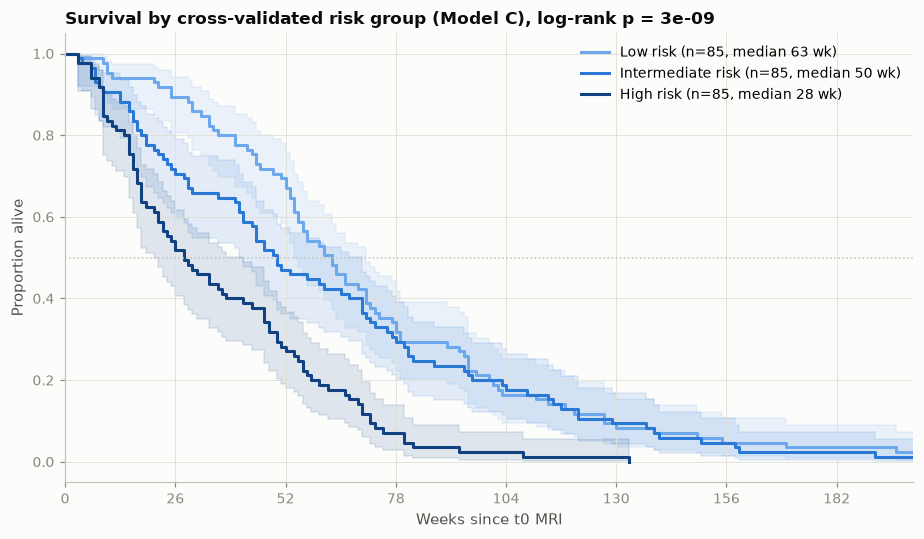

,n,"Median survival, weeks",Alive at 6 mo,Alive at 1 y,Alive at 2 y,Mean predicted median
Group,,,,,,
Low risk,85,63,89%,67%,16%,74
Intermediate risk,85,50,71%,47%,18%,52
High risk,85,28,52%,27%,2%,30


In [17]:
o = oof_avg[FINAL_NAME].copy()
o["group"] = pd.qcut(o["median"].rank(method="first"), 3, labels=["High risk", "Intermediate risk", "Low risk"])
fig, ax = plt.subplots(figsize=(8.5, 5))
grp_rows = []
for i, gname in enumerate(["Low risk", "Intermediate risk", "High risk"]):
    g = o[o.group == gname]; k = KaplanMeierFitter().fit(g.time, np.ones(len(g)))
    k.plot_survival_function(ax=ax, ci_show=True, color=ORD[i], label=f"{gname} (n={len(g)}, median {k.median_survival_time_:.0f} wk)", ci_alpha=0.12)
    grp_rows.append({"Group": gname, "n": len(g), "Median survival, weeks": k.median_survival_time_,
                     "Alive at 6 mo": k.predict(26), "Alive at 1 y": k.predict(52), "Alive at 2 y": k.predict(104),
                     "Mean predicted median": g["median"].mean()})
pv = multivariate_logrank_test(o.time, o.group, np.ones(len(o))).p_value
ax.axhline(0.5, color=AXIS, lw=1, ls=":")
ax.set_xlim(0, 200); ax.set_xticks([0, 26, 52, 78, 104, 130, 156, 182])
ax.set_xlabel("Weeks since t0 MRI"); ax.set_ylabel("Proportion alive")
ax.set_title(f"Survival by cross-validated risk group (Model C), log-rank p = {pv:.1g}", loc="left")
fig.tight_layout(); savefig(fig, "fig6_risk_groups"); plt.show()
grp = pd.DataFrame(grp_rows).set_index("Group")
display(grp.style.format({"Median survival, weeks": "{:.0f}", "Alive at 6 mo": "{:.0%}", "Alive at 1 y": "{:.0%}",
                          "Alive at 2 y": "{:.0%}", "Mean predicted median": "{:.0f}"}))

### 5.6 Individualized predictions
`predict_patient()` returns a full survival curve for a new patient, together with:
* **Predicted median survival**: the time at which the patient's predicted probability of being alive falls to 50%.
* **50% prediction interval**: the range between the 25th and 75th percentile of the predicted survival time. It shows how much individual outcomes vary even when the risk profile is known exactly.
* **Probability of being alive** at 6, 12 and 24 months.

Without FLAIR features it uses the bedside Model B. If a FLAIR feature vector is supplied (PyRadiomics, same settings, GTV mask at t0), it uses Model C.
`who2021=1` is the default because new patients are diagnosed under the current WHO 2021 classification.
Uncertainty in the model itself is shown with 95% bootstrap intervals (200 resamples, refitting the whole pipeline each time).

**Example predictions** (Model C with typical FLAIR texture; 200 successful bootstrap refits)

,Profile,Median (wk),95% CI,50% of patients die between (wk),Alive 6 mo,Alive 1 y,"1 y, 95% CI",Alive 2 y,Bedside Model B median (wk)
Patient,,,,,,,,,
A,"52 y, PS 0, conventional RT, 20 cm³",54,45–69,28–78,76%,52%,41%–64%,11%,61
B,"64 y, PS 1, conventional RT, 40 cm³",54,46–66,28–78,76%,52%,42%–64%,11%,55
C,"73 y, PS 2, hypofractionated RT, 60 cm³",29,18–44,16–50,54%,23%,9%–39%,1%,25
D,"79 y, PS 3, hypofractionated RT, 100 cm³",16,9–23,8–24,22%,3%,0%–12%,0%,14


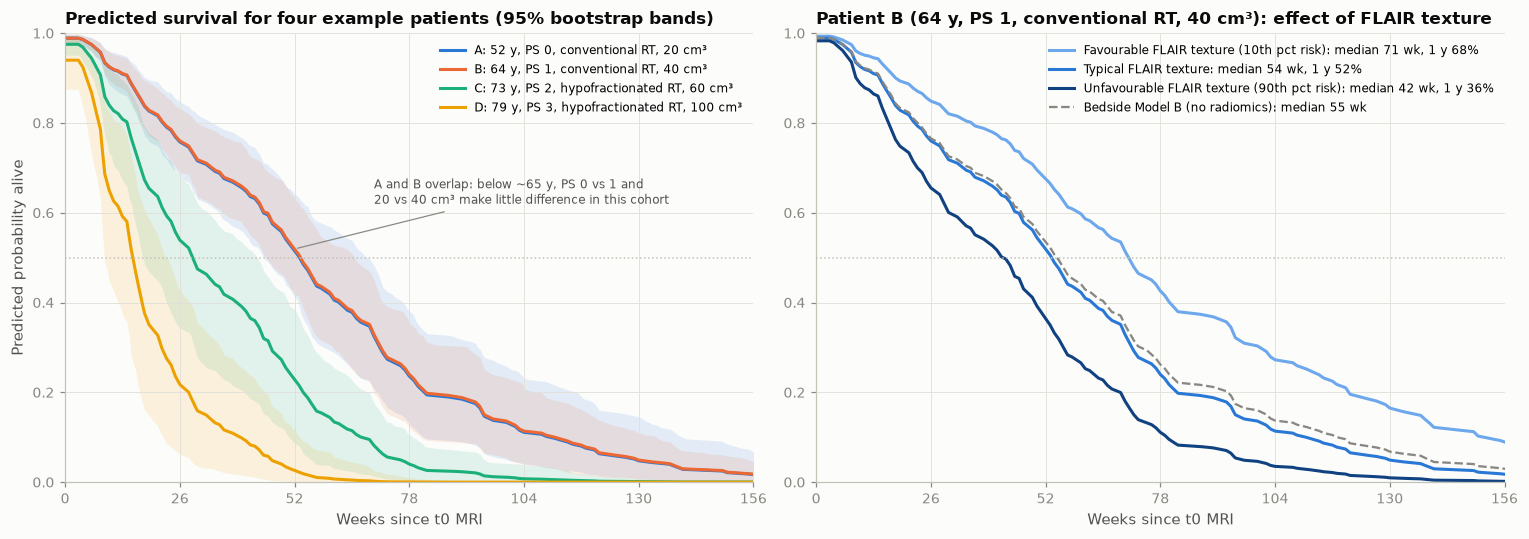

In [18]:
def make_patient(age, ps, regimen, volume_cm3, who2021=1, flair_features=None):
    row = {"age": age, "age10": (age - 65) / 10, "ps2": int(ps == 2), "ps3": int(ps == 3), "who2021": who2021,
           "hypo": int(regimen == "Hypofractionated"), "unk": int(regimen == "Unknown"),
           "lv": np.log2(volume_cm3) - np.log2(30), "time": np.nan, "event": np.nan}
    p = pd.DataFrame([row])
    if flair_features is not None:
        p = p.join(pd.DataFrame([pd.Series(flair_features)[flair.columns].values], columns=flair.columns))
    return p

def summarize_curve(S):
    t_at = lambda level: GRID[np.argmax(S <= level)] if (S <= level).any() else np.nan
    return {"Median, weeks": t_at(0.5), "50% PI low": t_at(0.75), "50% PI high": t_at(0.25),
            "Alive 6 mo": S[I26], "Alive 1 y": S[I52], "Alive 2 y": S[I104]}

def predict_patient(age, ps, regimen, volume_cm3, who2021=1, flair_features=None, model=None):
    """Individualized survival prediction. regimen: 'Conventional' | 'Hypofractionated' | 'Unknown'."""
    p = make_patient(age, ps, regimen, volume_cm3, who2021, flair_features)
    model = model or (final if flair_features is not None else bedside)
    S = model.survival(p)[0]
    return S, summarize_curve(S)

examples = pd.DataFrame([
    {"Patient": "A", "age": 52, "ps": 0, "regimen": "Conventional", "volume_cm3": 20},
    {"Patient": "B", "age": 64, "ps": 1, "regimen": "Conventional", "volume_cm3": 40},
    {"Patient": "C", "age": 73, "ps": 2, "regimen": "Hypofractionated", "volume_cm3": 60},
    {"Patient": "D", "age": 79, "ps": 3, "regimen": "Hypofractionated", "volume_cm3": 100},
]).set_index("Patient")

# FLAIR texture profiles: the cohort's typical (feature-wise median) texture, and the actual texture vectors of the
# patients at the 10th / 90th percentile of the Model C radiomic risk score
Xc = final._X(cvdat); pcs = [f"PC{i + 1}" for i in range(5)]
rad_score = Xc[pcs] @ final.cph.params_[pcs]
typical_flair = flair.loc[cvdat.index].median()
fav_flair = flair.loc[(rad_score - rad_score.quantile(0.10)).abs().idxmin()]
unfav_flair = flair.loc[(rad_score - rad_score.quantile(0.90)).abs().idxmin()]

rng = np.random.default_rng(SEED)
B = 200
boot_S = {p: [] for p in examples.index}
for b in range(B):
    idx = rng.choice(len(cvdat), len(cvdat), replace=True)
    bd = cvdat.iloc[idx].copy(); bd.index = np.arange(len(bd))
    bflair = flair.loc[cvdat.index[idx]].copy(); bflair.index = bd.index
    bd = bd.join(bflair)
    try:
        bm = CoxModel(ClinicalDesign(volume=True, spline=True), flair_pcs=5).fit(bd)
    except Exception:
        continue
    for pid, e in examples.iterrows():
        boot_S[pid].append(bm.survival(make_patient(e.age, e.ps, e.regimen, e.volume_cm3, 1, typical_flair))[0])

pred_rows, curves = [], {}
for pid, e in examples.iterrows():
    S, summ = predict_patient(e.age, e.ps, e.regimen, e.volume_cm3, flair_features=typical_flair)
    Sb = np.array(boot_S[pid]); curves[pid] = (S, np.percentile(Sb, 2.5, 0), np.percentile(Sb, 97.5, 0))
    meds = np.array([summarize_curve(s)["Median, weeks"] for s in Sb])
    _, summ_bed = predict_patient(e.age, e.ps, e.regimen, e.volume_cm3)
    pred_rows.append({"Patient": pid, "Profile": f"{e.age} y, PS {e.ps}, {e.regimen.lower()} RT, {e.volume_cm3} cm³",
                      "Median (wk)": summ["Median, weeks"],
                      "95% CI": f"{np.nanpercentile(meds, 2.5):.0f}–{np.nanpercentile(meds, 97.5):.0f}",
                      "50% of patients die between (wk)": f"{summ['50% PI low']:.0f}–{summ['50% PI high']:.0f}",
                      "Alive 6 mo": summ["Alive 6 mo"],
                      "Alive 1 y": summ["Alive 1 y"],
                      "1 y, 95% CI": f"{np.percentile(Sb[:, I52], 2.5):.0%}–{np.percentile(Sb[:, I52], 97.5):.0%}",
                      "Alive 2 y": summ["Alive 2 y"],
                      "Bedside Model B median (wk)": summ_bed["Median, weeks"]})
pred_tab = pd.DataFrame(pred_rows).set_index("Patient")
pred_tab.to_csv(OUT / "table8_example_predictions.csv")
display(Markdown(f"**Example predictions** (Model C with typical FLAIR texture; {len(boot_S['A'])} successful bootstrap refits)"))
display(pred_tab.style.format({"Median (wk)": "{:.0f}", "Alive 6 mo": "{:.0%}", "Alive 1 y": "{:.0%}", "Alive 2 y": "{:.0%}",
                               "Bedside Model B median (wk)": "{:.0f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for i, pid in enumerate(examples.index):
    S, lo, hi = curves[pid]
    ax.fill_between(GRID, lo, hi, color=C[i], alpha=0.12, lw=0)
    ax.plot(GRID, S, color=C[i], label=f"{pid}: {pred_tab.loc[pid, 'Profile']}")
ax.axhline(0.5, color=AXIS, lw=1, ls=":")
ax.set_xlim(0, 156); ax.set_xticks([0, 26, 52, 78, 104, 130, 156]); ax.set_ylim(0, 1)
ax.set_xlabel("Weeks since t0 MRI"); ax.set_ylabel("Predicted probability alive")
ax.set_title("Predicted survival for four example patients (95% bootstrap bands)", loc="left"); ax.legend(loc="upper right", fontsize=8)
ax.annotate("A and B overlap: below ~65 y, PS 0 vs 1 and\n20 vs 40 cm³ make little difference in this cohort",
            xy=(52, curves["B"][0][I52]), xytext=(70, 0.62), fontsize=8, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))

ax = axes[1]
e = examples.loc["B"]
for i, (lab, fv) in enumerate([("Favourable FLAIR texture (10th pct risk)", fav_flair), ("Typical FLAIR texture", typical_flair),
                               ("Unfavourable FLAIR texture (90th pct risk)", unfav_flair)]):
    S, summ = predict_patient(e.age, e.ps, e.regimen, e.volume_cm3, flair_features=fv)
    ax.plot(GRID, S, color=ORD[i], label=f"{lab}: median {summ['Median, weeks']:.0f} wk, 1 y {summ['Alive 1 y']:.0%}")
S, summ = predict_patient(e.age, e.ps, e.regimen, e.volume_cm3)
ax.plot(GRID, S, color=MUTED, ls="--", lw=1.5, label=f"Bedside Model B (no radiomics): median {summ['Median, weeks']:.0f} wk")
ax.axhline(0.5, color=AXIS, lw=1, ls=":")
ax.set_xlim(0, 156); ax.set_xticks([0, 26, 52, 78, 104, 130, 156]); ax.set_ylim(0, 1)
ax.set_xlabel("Weeks since t0 MRI"); ax.set_title(f"Patient B ({pred_tab.loc['B', 'Profile']}): effect of FLAIR texture", loc="left")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout(); savefig(fig, "fig7_individual_predictions"); plt.show()

## 6. Additional analyses
### 6.1 Early response on the first follow-up MRI (exploratory, *not* a baseline predictor)
RANO response between t0 and t1 is only known for patients who **survived long enough to have a t1 scan**. Patients with a t1 assessment had a median survival of 56 weeks vs 29 weeks for those without (printed below).
Using response as a baseline predictor would therefore create **immortal-time bias**. Instead we ask: *among patients who reached the first follow-up MRI, does early progression add information beyond the baseline factors?* This is the question a physician faces at that visit.
Caveats: the exact date of t1 is not in the shared files, so a formal landmark analysis is not possible. And radiological "progression" soon after chemoradiation is partly **pseudoprogression**.

Median survival with vs without a t1 RANO assessment: 56 vs 29 weeks


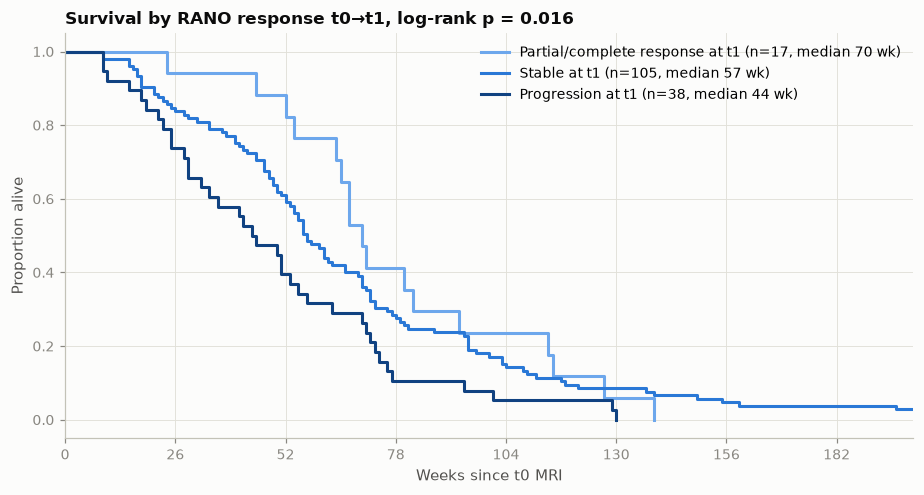

**Adjusted for age, PS, WHO edition, RT regimen and baseline volume** (n = 160)

,HR,95% CI low,95% CI high,p
Progression at t1 (vs stable),2.16,1.42,3.28,0.000292
Partial/complete response at t1 (vs stable),0.75,0.44,1.27,0.29
Tumour volume change t0→t1 (per doubling),1.27,1.06,1.51,0.00927


In [19]:
r = dm[dm.rano_t0_to_t1.notna()].copy()
r["resp"] = r.rano_t0_to_t1.str.extract(r"\((\w+)\)")[0].replace({"CR": "PR"}).map({"PD": "Progression", "SD": "Stable", "PR": "Partial/complete response"})
r["PD"] = (r.resp == "Progression").astype(int); r["PRCR"] = (r.resp == "Partial/complete response").astype(int)
r["vol_change_doublings"] = np.log2(r["size_t1 (cm3)"].clip(lower=0.1) / r["size_t0 (cm3)"])
print(f"Median survival with vs without a t1 RANO assessment: {r.time.median():.0f} vs "
      f"{dm.loc[~dm.index.isin(r.index), 'time'].median():.0f} weeks")
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for i, lev in enumerate(["Partial/complete response", "Stable", "Progression"]):
    g = r[r.resp == lev]; k = KaplanMeierFitter().fit(g.time, g.event)
    k.plot_survival_function(ax=ax, ci_show=False, color=ORD[i], label=f"{lev} at t1 (n={len(g)}, median {k.median_survival_time_:.0f} wk)")
ax.set_xlim(0, 200); ax.set_xticks([0, 26, 52, 78, 104, 130, 156, 182])
ax.set_xlabel("Weeks since t0 MRI"); ax.set_ylabel("Proportion alive")
ax.set_title(f"Survival by RANO response t0→t1, log-rank p = {multivariate_logrank_test(r.time, r.resp, r.event).p_value:.2g}", loc="left")
fig.tight_layout(); savefig(fig, "fig8_rano_t1"); plt.show()
Xr = ClinicalDesign(volume=True, spline=False).fit(r).transform(r)
s1 = CoxPHFitter().fit(Xr.assign(PD=r.PD, PRCR=r.PRCR, time=r.time, event=r.event), "time", "event").summary
s2 = CoxPHFitter().fit(Xr.assign(chg=r.vol_change_doublings, time=r.time, event=r.event), "time", "event").summary
rt = pd.DataFrame({"HR": [s1.loc["PD", "exp(coef)"], s1.loc["PRCR", "exp(coef)"], s2.loc["chg", "exp(coef)"]],
                   "95% CI low": [s1.loc["PD", "exp(coef) lower 95%"], s1.loc["PRCR", "exp(coef) lower 95%"], s2.loc["chg", "exp(coef) lower 95%"]],
                   "95% CI high": [s1.loc["PD", "exp(coef) upper 95%"], s1.loc["PRCR", "exp(coef) upper 95%"], s2.loc["chg", "exp(coef) upper 95%"]],
                   "p": [s1.loc["PD", "p"], s1.loc["PRCR", "p"], s2.loc["chg", "p"]]},
                  index=["Progression at t1 (vs stable)", "Partial/complete response at t1 (vs stable)", "Tumour volume change t0→t1 (per doubling)"])
display(Markdown(f"**Adjusted for age, PS, WHO edition, RT regimen and baseline volume** (n = {len(r)})"))
display(rt.style.format({"HR": "{:.2f}", "95% CI low": "{:.2f}", "95% CI high": "{:.2f}", "p": "{:.3g}"}))

### 6.2 A counter-intuitive finding: a longer wait before radiotherapy goes with *longer* survival
Each extra week between diagnosis and the start of radiotherapy is associated with *lower* hazard. This is almost certainly **confounding by indication**, not a benefit of delay: the sickest patients (worse PS, more symptomatic) are started urgently. It is a good example of why the treatment variables in this observational dataset must not be read causally. The same applies to the hypofractionated regimen, which is chosen for older and frailer patients.

In [20]:
dl = df[df.rt_delay.notna()].copy()
dl["Delay to RT"] = pd.cut(dl.rt_delay, [-1, 0, 1, 2, 10], labels=["0 wk", "1 wk", "2 wk", "≥3 wk"])
display(dl.groupby("Delay to RT", observed=True).agg(n=("time", "size"), **{"Median survival (wk)": ("time", "median"),
        "Mean PS": ("ps", "mean"), "% PS ≥ 2": ("ps", lambda x: (x >= 2).mean() * 100), "Median age": ("age", "median")})
        .style.format({"Median survival (wk)": "{:.0f}", "Mean PS": "{:.2f}", "% PS ≥ 2": "{:.0f}%", "Median age": "{:.0f}"}))

,n,Median survival (wk),Mean PS,% PS ≥ 2,Median age
Delay to RT,,,,,
0 wk,12,20,2.00,75%,75
1 wk,89,48,1.16,30%,70
2 wk,80,56,1.05,22%,70
≥3 wk,13,73,1.08,23%,70


## 7. Body size, sex and fitness: links with the tumour, treatment, response and survival
Questions examined here:
1. Is **body mass** (BMI, height, weight) related to tumour size, fitness (performance status), the treatment received, tumour response, or survival? Low body weight can reflect *cachexia*, the cancer-related wasting that often signals advanced or aggressive disease. Higher BMI has been linked with better outcomes in some cancers (the "obesity paradox").
2. Does **sex** relate to the treatment received (regimen, delay to RT) or to response and survival?
3. Do **dose and body mass together** relate to tumour shrinkage? Radiotherapy dose is not weight-based (see *Gray* in the glossary). The meaningful question is whether patients of different size **respond differently to the same schedule**, which is tested as an interaction (regimen × BMI).
4. Is BMI a marker of "healthiness", i.e. does it track performance status, and does fitness relate to treatment and response?

**Outcomes and models.** Every model adjusts for the main prognostic factors, so each effect is "all else equal".

| Outcome | Patients | Model | Effect reported | Adjusted for |
|---|---|---|---|---|
| Survival | 261 | Cox | HR (> 1 = shorter survival) | age, PS, WHO edition, RT regimen, tumour volume |
| Worse performance status | 261 | Ordinal logistic | OR of being one PS level worse | age, tumour volume |
| Receiving hypofractionated RT | treated patients | Logistic | OR | age, PS, WHO edition, tumour volume |
| Tumour volume change t0 → t1 | 160 with a t1 scan | Linear regression on log₂(V₁/V₀), robust SEs | Ratio of post/pre volume (< 1 = more shrinkage) | RT regimen, age, PS, WHO edition, baseline volume |
| Progression at t1 (RANO PD) | 160 | Logistic | OR | as above |

*Why log₂(V₁/V₀) rather than the supplied `reduction_rate`?* The reduction rate (V₀ − V₁)/V₀ is lopsided. Shrinkage can be at most 100%, but growth is unlimited (it reaches −617% here), so a few growing tumours would dominate any average. On the log scale, halving and doubling are equally large steps in opposite directions.

In [21]:
import statsmodels.formula.api as smf
from statsmodels.miscmodels.ordinal_model import OrderedModel

bx = dm.copy()
bx["bmi_cat"] = pd.cut(bx.bmi, [0, 18.5, 25, 30, 100], right=False,
                       labels=["Underweight (<18.5)", "Normal (18.5–25)", "Overweight (25–30)", "Obese (≥30)"])
bx["under"] = (bx.bmi < 18.5).astype(int); bx["over"] = bx.bmi.between(25, 30, inclusive="left").astype(int)
bx["obese"] = (bx.bmi >= 30).astype(int)
bx["height10"], bx["weight10"] = bx.height / 10, bx.weight / 10
bx["growth"] = np.log2(bx["size_t1 (cm3)"].clip(lower=0.1) / bx["size_t0 (cm3)"])
bx["PD1"] = bx.rano_t0_to_t1.str.contains("PD").astype(float).where(bx.rano_t0_to_t1.notna())

def describe(g):
    treated = g[g.regimen != "Unknown"]
    return pd.Series({"n": len(g), "Male": (g.male == 1).mean(), "Median age": g.age.median(), "PS ≥ 2": (g.ps >= 2).mean(),
                      "Median tumour volume, cm³": g.vol.median(),
                      "Hypofractionated (of treated)": (treated.regimen == "Hypofractionated").mean(),
                      "Median delay to RT, wk": g.rt_delay.median(),
                      "Median volume change t0→t1": 2 ** g.growth.median() - 1,
                      "Progression at t1": g.PD1.mean(), "Median survival, wk": g.time.median()})

desc = pd.concat({**{str(k): describe(g) for k, g in bx.groupby("bmi_cat", observed=True)},
                  "Female": describe(bx[bx.male == 0]), "Male ": describe(bx[bx.male == 1])}, axis=1)
desc.to_csv(OUT / "table9_body_size_sex_descriptives.csv")
pct = ["Male", "PS ≥ 2", "Hypofractionated (of treated)", "Median volume change t0→t1", "Progression at t1"]
display(Markdown("**Descriptive overview by BMI category and by sex** (volume change: negative = shrinkage)"))
display(desc.style.format(lambda v: f"{v:.0f}", subset=pd.IndexSlice[[r for r in desc.index if r not in pct], :])
        .format(lambda v: f"{v:+.0%}" if v == v else "–", subset=pd.IndexSlice[["Median volume change t0→t1"], :])
        .format(lambda v: f"{v:.0%}", subset=pd.IndexSlice[[p for p in pct if p != "Median volume change t0→t1"], :]))
rho, p_rho = stats.spearmanr(bx.bmi, bx.ps)
print(f"BMI vs performance status: Spearman rho = {rho:.2f} (p = {p_rho:.2f})")
print(f"Regimen by sex: chi-square p = {stats.chi2_contingency(pd.crosstab(bx.male, bx.regimen))[1]:.2f} (unadjusted)")

**Descriptive overview by BMI category and by sex** (volume change: negative = shrinkage)

,Underweight (<18.5),Normal (18.5–25),Overweight (25–30),Obese (≥30),Female,Male
n,14,116,98,33,104,157
Male,29%,65%,63%,48%,0%,100%
Median age,68,70,70,70,70,70
PS ≥ 2,43%,32%,33%,30%,34%,32%
"Median tumour volume, cm³",38,38,36,34,34,42
Hypofractionated (of treated),29%,35%,33%,27%,39%,29%
"Median delay to RT, wk",1,1,1,2,1,1
Median volume change t0→t1,+6%,-13%,-14%,-10%,-1%,-16%
Progression at t1,17%,23%,22%,31%,28%,21%
"Median survival, wk",32,50,44,57,47,51


BMI vs performance status: Spearman rho = -0.03 (p = 0.61)
Regimen by sex: chi-square p = 0.29 (unadjusted)


### 7.1 Adjusted associations of sex and body mass across five outcomes
Each exposure is entered two ways: BMI as a continuous variable (per +5 kg/m²), and BMI categories compared with normal weight (in a separate model).
Age is shown in grey as a yardstick for what a genuine association looks like in the same model.

**Adjusted effects** (estimate, 95% CI; * p < 0.05). 1.00 = no association

,"Survival (HR), n=261","Worse PS (OR), n=261","Hypofractionated RT (OR), n=194","Tumour volume ratio t1/t0, n=160","Progression at t1 (OR), n=160"
Exposure,,,,,
Male (vs female),0.99 (0.76–1.29),0.89 (0.56–1.42),0.67 (0.29–1.55),0.94 (0.73–1.21),0.52 (0.23–1.21)
"BMI, per +5 kg/m²",1.01 (0.87–1.17),0.96 (0.74–1.24),0.62 (0.38–1.02),1.00 (0.86–1.16),1.30 (0.83–2.04)
Underweight (vs normal),0.97 (0.52–1.80),1.32 (0.44–3.95),2.05 (0.23–18.40),0.91 (0.44–1.87),0.66 (0.06–6.81)
Overweight (vs normal),1.30 (0.99–1.72),0.99 (0.60–1.64),0.95 (0.39–2.31),0.97 (0.73–1.27),0.72 (0.28–1.90)
Obese (vs normal),0.88 (0.59–1.31),0.81 (0.39–1.69),0.62 (0.18–2.09),0.89 (0.57–1.37),1.32 (0.43–4.06)
"Height, per +10 cm",1.09 (0.88–1.35),1.05 (0.72–1.54),1.19 (0.59–2.40),1.11 (0.83–1.48),0.55 (0.28–1.08)
"Weight, per +10 kg",1.01 (0.91–1.13),0.96 (0.79–1.16),0.71 (0.49–1.01),1.02 (0.92–1.12),1.17 (0.85–1.63)
"Age, per +10 years (yardstick)",1.20 (1.04–1.39) *,1.39 (1.12–1.72) *,9.42 (4.71–18.85) *,1.11 (0.90–1.37),1.02 (0.67–1.54)


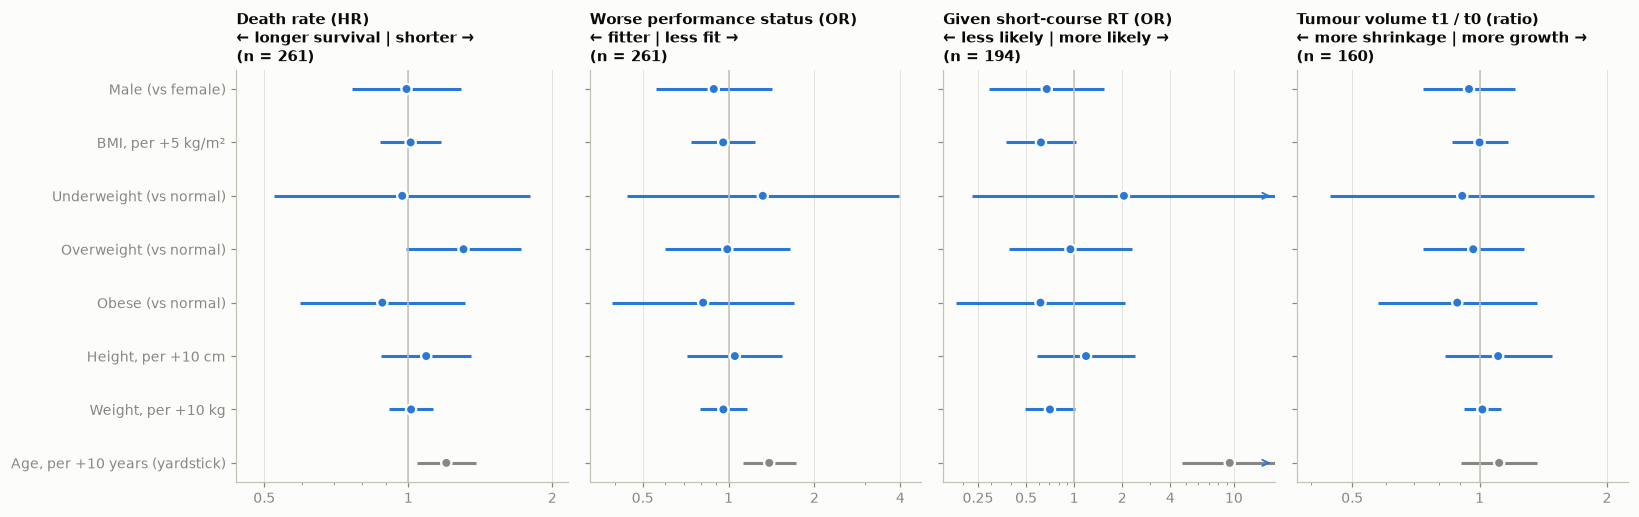

In [22]:
SURV_ADJ = "age10 + ps2 + ps3 + who2021 + hypo + unk + lv"

def fit_outcome(outcome, exposures):
    """Fit one adjusted model; returns {term: (estimate, low, high, p)} on the ratio scale, plus n."""
    if outcome == "Survival (HR)":
        d = bx; f = f"{exposures} + {SURV_ADJ}"
        res = CoxPHFitter().fit(d, "time", "event", formula=f).summary
        out = {t: (r["exp(coef)"], r["exp(coef) lower 95%"], r["exp(coef) upper 95%"], r["p"]) for t, r in res.iterrows()}
        return out, len(d)
    if outcome == "Worse PS (OR)":
        d = bx
        cols = [c.strip() for c in f"{exposures} + age10 + lv".split("+")]
        m = OrderedModel(d.ps.astype(int), d[cols].astype(float), distr="logit").fit(method="bfgs", disp=False)
        ci = m.conf_int()
        return {t: (np.exp(m.params[t]), np.exp(ci.loc[t, 0]), np.exp(ci.loc[t, 1]), m.pvalues[t]) for t in cols}, len(d)
    if outcome == "Hypofractionated RT (OR)":
        d = bx[bx.regimen != "Unknown"]
        m = smf.logit(f"hypo ~ {exposures} + age10 + ps2 + ps3 + who2021 + lv", d).fit(disp=False)
    elif outcome == "Tumour volume ratio t1/t0":
        d = bx.dropna(subset=["growth"])
        m = smf.ols(f"growth ~ {exposures} + {SURV_ADJ}", d).fit(cov_type="HC3")
        ci = m.conf_int()
        return {t: (2 ** m.params[t], 2 ** ci.loc[t, 0], 2 ** ci.loc[t, 1], m.pvalues[t]) for t in m.params.index}, len(d)
    elif outcome == "Progression at t1 (OR)":
        d = bx.dropna(subset=["PD1"])
        m = smf.logit(f"PD1 ~ {exposures} + {SURV_ADJ}", d).fit(disp=False)
    ci = m.conf_int()
    return {t: (np.exp(m.params[t]), np.exp(ci.loc[t, 0]), np.exp(ci.loc[t, 1]), m.pvalues[t]) for t in m.params.index}, len(d)

OUTCOMES = ["Survival (HR)", "Worse PS (OR)", "Hypofractionated RT (OR)", "Tumour volume ratio t1/t0", "Progression at t1 (OR)"]
ROWS = [("male", "Male (vs female)", "male + bmi5"), ("bmi5", "BMI, per +5 kg/m²", "male + bmi5"),
        ("under", "Underweight (vs normal)", "male + under + over + obese"),
        ("over", "Overweight (vs normal)", "male + under + over + obese"),
        ("obese", "Obese (vs normal)", "male + under + over + obese"),
        ("height10", "Height, per +10 cm", "male + height10 + weight10"),
        ("weight10", "Weight, per +10 kg", "male + height10 + weight10"),
        ("age10", "Age, per +10 years (yardstick)", "male + bmi5")]
assoc, n_by = [], {}
for oc in OUTCOMES:
    cache_fits = {}
    for term, label, exp_ in ROWS:
        if exp_ not in cache_fits:
            cache_fits[exp_] = fit_outcome(oc, exp_)
        res, n = cache_fits[exp_]; n_by[oc] = n
        est, lo, hi, p = res[term]
        assoc.append({"Outcome": oc, "Exposure": label, "Estimate": est, "95% CI low": lo, "95% CI high": hi, "p": p})
assoc = pd.DataFrame(assoc)
assoc.to_csv(OUT / "table10_body_size_sex_associations.csv", index=False)

wide = assoc.assign(cell=lambda a: a.apply(lambda r: f"{r.Estimate:.2f} ({r['95% CI low']:.2f}–{r['95% CI high']:.2f}){' *' if r.p < 0.05 else ''}", axis=1)) \
            .pivot(index="Exposure", columns="Outcome", values="cell").loc[[r[1] for r in ROWS], OUTCOMES]
wide.columns = [f"{c}, n={n_by[c]}" for c in wide.columns]
display(Markdown("**Adjusted effects** (estimate, 95% CI; * p < 0.05). 1.00 = no association"))
display(wide)

PANELS = ["Survival (HR)", "Worse PS (OR)", "Hypofractionated RT (OR)", "Tumour volume ratio t1/t0"]
TITLES = {"Survival (HR)": "Death rate (HR)\n← longer survival | shorter →",
          "Worse PS (OR)": "Worse performance status (OR)\n← fitter | less fit →",
          "Hypofractionated RT (OR)": "Given short-course RT (OR)\n← less likely | more likely →",
          "Tumour volume ratio t1/t0": "Tumour volume t1 / t0 (ratio)\n← more shrinkage | more growth →"}
labels = [r[1] for r in ROWS]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.8), sharey=True)
for ax, oc in zip(axes, PANELS):
    a = assoc[assoc.Outcome == oc].set_index("Exposure").loc[labels]
    y = np.arange(len(labels))[::-1]
    col = [MUTED if "yardstick" in l else C[0] for l in labels]
    ax.hlines(y, a["95% CI low"], a["95% CI high"], color=col, lw=2)
    ax.scatter(a.Estimate, y, color=col, s=45, zorder=3, edgecolor=SURF, linewidth=1.5)
    ax.axvline(1, color=AXIS, lw=1)
    ax.set_xscale("log")
    lo_, hi_ = max(a["95% CI low"].min(), 0.08), min(a["95% CI high"].max(), 15)
    ax.set_xlim(lo_ / 1.2, hi_ * 1.2)
    ticks = [t for t in [0.1, 0.25, 0.5, 1, 2, 4, 10] if lo_ / 1.2 <= t <= hi_ * 1.2]
    ax.set_xticks(ticks); ax.set_xticklabels([f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    for yi, (e, h) in zip(y, zip(a["95% CI high"], a.Estimate)):
        if e > hi_ * 1.2:
            ax.annotate("", xy=(hi_ * 1.18, yi), xytext=(hi_ * 1.05, yi), arrowprops=dict(arrowstyle="->", color=C[0], lw=1.2))
    ax.set_title(f"{TITLES[oc]}\n(n = {n_by[oc]})", loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(labels))[::-1]); axes[0].set_yticklabels(labels)
fig.tight_layout(); savefig(fig, "fig9_body_size_sex_forest"); plt.show()

### 7.2 Sex, fitness and the radiotherapy received
Which patient characteristics determine **which schedule** a patient gets and **how quickly** treatment starts? (Treated patients only.)

In [23]:
m_hypo = smf.logit("hypo ~ age10 + ps2 + ps3 + male + bmi5 + who2021 + lv", bx[bx.regimen != "Unknown"]).fit(disp=False)
m_delay = smf.ols("rt_delay ~ age10 + ps2 + ps3 + male + bmi5 + hypo", bx[bx.regimen != "Unknown"]).fit(cov_type="HC3")
nice = {"age10": "Age, per +10 years", "ps2": "PS 2 (vs 0–1)", "ps3": "PS 3 (vs 0–1)", "male": "Male (vs female)",
        "bmi5": "BMI, per +5 kg/m²", "who2021": "WHO 2021 classification", "lv": "Tumour volume, per doubling",
        "hypo": "Hypofractionated RT"}
ci_h, ci_d = m_hypo.conf_int(), m_delay.conf_int()
tt = pd.DataFrame({"OR of hypofractionated RT": np.exp(m_hypo.params), "OR 95% CI": [f"{np.exp(a):.2f}–{np.exp(b):.2f}" for a, b in ci_h.values],
                   "p (OR)": m_hypo.pvalues}).drop("Intercept")
td = pd.DataFrame({"Δ delay to RT, weeks": m_delay.params, "Δ 95% CI": [f"{a:+.2f} to {b:+.2f}" for a, b in ci_d.values],
                   "p (delay)": m_delay.pvalues}).drop("Intercept")
tt = tt.join(td, how="outer").rename(index=nice).loc[[v for v in nice.values()]]
display(Markdown(f"**Treatment allocation** (logistic, n = {int(m_hypo.nobs)}) and **delay to radiotherapy** (linear, n = {int(m_delay.nobs)})"))
display(tt.style.format({"OR of hypofractionated RT": "{:.2f}", "p (OR)": "{:.3g}", "Δ delay to RT, weeks": "{:+.2f}", "p (delay)": "{:.3g}"}, na_rep="–"))

**Treatment allocation** (logistic, n = 194) and **delay to radiotherapy** (linear, n = 194)

,OR of hypofractionated RT,OR 95% CI,p (OR),"Δ delay to RT, weeks",Δ 95% CI,p (delay)
"Age, per +10 years",9.42,4.71–18.85,2.35e-10,+0.01,-0.12 to +0.14,0.859
PS 2 (vs 0–1),1.67,0.65–4.26,0.284,-0.26,-0.53 to +0.00,0.0508
PS 3 (vs 0–1),1.95,0.30–12.81,0.485,-0.69,-1.31 to -0.08,0.0259
Male (vs female),0.67,0.29–1.55,0.351,+0.08,-0.15 to +0.31,0.482
"BMI, per +5 kg/m²",0.62,0.38–1.02,0.06,+0.02,-0.10 to +0.14,0.79
WHO 2021 classification,0.62,0.25–1.53,0.296,–,–,–
"Tumour volume, per doubling",1.28,0.93–1.76,0.134,–,–,–
Hypofractionated RT,–,–,–,-0.20,-0.51 to +0.11,0.206


### 7.3 Do body size or sex change how well the treatment works? (interaction tests)
An interaction asks whether the effect of the RT regimen **differs** between, say, heavier and lighter patients, or between women and men. This is the statistically correct way to ask whether "dose and mass" act together.
Caveats: these tests have low power with 36 hypofractionated patients who had a t1 scan, and the timing of the t1 scan relative to treatment may differ between the 3-week and 6-week schedules.

In [24]:
inter = []
dr = bx.dropna(subset=["growth"])
for label, f_full, term in [
        ("Tumour volume change × BMI", "growth ~ hypo*bmi5 + unk + male + age10 + ps2 + ps3 + who2021 + lv", "hypo:bmi5"),
        ("Tumour volume change × sex", "growth ~ hypo*male + unk + bmi5 + age10 + ps2 + ps3 + who2021 + lv", "hypo:male")]:
    m = smf.ols(f_full, dr).fit(cov_type="HC3")
    inter.append({"Outcome × modifier": label, "Interaction (ratio)": 2 ** m.params[term],
                  "95% CI": f"{2 ** m.conf_int().loc[term, 0]:.2f}–{2 ** m.conf_int().loc[term, 1]:.2f}", "p": m.pvalues[term], "n": int(m.nobs)})
for label, f_full, term in [("Survival × BMI", f"hypo*bmi5 + male + age10 + ps2 + ps3 + who2021 + unk + lv", "hypo:bmi5"),
                            ("Survival × sex", f"hypo*male + bmi5 + age10 + ps2 + ps3 + who2021 + unk + lv", "hypo:male")]:
    s_ = CoxPHFitter().fit(bx, "time", "event", formula=f_full).summary.loc[term]
    inter.append({"Outcome × modifier": label, "Interaction (ratio)": s_["exp(coef)"],
                  "95% CI": f"{s_['exp(coef) lower 95%']:.2f}–{s_['exp(coef) upper 95%']:.2f}", "p": s_["p"], "n": len(bx)})
inter = pd.DataFrame(inter).set_index("Outcome × modifier")
display(Markdown("**Does the effect of hypofractionated (vs conventional) RT differ by body size or sex?** A ratio of 1 means no difference."))
display(inter.style.format({"Interaction (ratio)": "{:.2f}", "p": "{:.2f}"}))

**Does the effect of hypofractionated (vs conventional) RT differ by body size or sex?** A ratio of 1 means no difference.

,Interaction (ratio),95% CI,p,n
Outcome × modifier,,,,
Tumour volume change × BMI,1.31,0.89–1.92,0.17,160
Tumour volume change × sex,0.88,0.48–1.63,0.69,160
Survival × BMI,0.85,0.59–1.24,0.40,261
Survival × sex,0.78,0.44–1.41,0.42,261


### 7.4 What does predict early shrinkage? A warning about baseline size
In the response models, the only baseline factor associated with response is **baseline tumour volume**. It is strongly linked to RANO progression (larger tumours are much less often classed as progressing) and weakly to the continuous volume ratio.
This should **not** be read as large tumours responding better. Two statistical effects produce the same pattern:
* **Regression to the mean**: tumours that happened to measure large at t0 (partly through measurement noise or swelling) tend to measure smaller next time.
* **Relative thresholds**: RANO progression means growth of ≥ 25%. For a 5 cm³ tumour, 1.25 cm³ of growth (often within segmentation error) already counts as progression; for a 60 cm³ tumour it takes 15 cm³.

In [25]:
mg = smf.ols(f"growth ~ male + bmi5 + {SURV_ADJ}", dr).fit(cov_type="HC3")
mp = smf.logit(f"PD1 ~ male + bmi5 + {SURV_ADJ}", bx.dropna(subset=["PD1"])).fit(disp=False)
print(f"Per doubling of baseline volume: t1/t0 volume ratio × {2 ** mg.params['lv']:.2f} "
      f"(95% CI {2 ** mg.conf_int().loc['lv', 0]:.2f}–{2 ** mg.conf_int().loc['lv', 1]:.2f}, p = {mg.pvalues['lv']:.3f}); "
      f"odds of progression at t1 × {np.exp(mp.params['lv']):.2f} "
      f"(95% CI {np.exp(mp.conf_int().loc['lv', 0]):.2f}–{np.exp(mp.conf_int().loc['lv', 1]):.2f}, p = {mp.pvalues['lv']:.2g})")
print(f"Progression at t1 by baseline-volume tertile: "
      + ", ".join(f"{k}: {v:.0%}" for k, v in bx.dropna(subset=["PD1"]).groupby(pd.qcut(bx.vol, 3, labels=["small", "medium", "large"]), observed=True).PD1.mean().items()))

Per doubling of baseline volume: t1/t0 volume ratio × 0.88 (95% CI 0.76–1.02, p = 0.083); odds of progression at t1 × 0.50 (95% CI 0.36–0.69, p = 3.1e-05)
Progression at t1 by baseline-volume tertile: small: 43%, medium: 17%, large: 10%


### 7.5 What this section shows
* **Body mass does not track fitness here.** BMI is essentially uncorrelated with performance status, so it is not a usable proxy for "healthiness" in this cohort. **Performance status and age** are the fitness measures that matter.
* **Body mass and height are not associated with tumour size, response or survival** after adjustment. The 14 underweight patients have a shorter median survival, but their hazard ratio is close to 1 with a very wide CI. The group is too small to say more, and cachexia remains plausible.
* **Sex is not associated with treatment received, delay to treatment, response or survival**, and the treatment effect does not differ by sex. Women received the short course slightly more often in raw numbers, which is explained by chance and age.
* **Treatment choice is driven by age.** The odds of hypofractionated RT rise roughly 9-fold per decade, with a weaker signal for lower BMI. This confirms that regimen in the survival model largely stands in for age and frailty.
* **Sicker patients start RT sooner.** PS 3 patients start ~0.7 weeks earlier, which explains the "longer delay, longer survival" paradox in §6.2.
* **Nothing measured at baseline predicts early shrinkage**, apart from the baseline-size artefact. That includes regimen, BMI, sex, age and PS. There is no evidence that the effect of the schedule depends on body size or sex.
* **Absence of evidence is not evidence of absence.** Several CIs are wide (e.g. underweight, obese, interactions), so moderate effects cannot be ruled out with 160–264 patients. These are exploratory analyses with many tests; a single p < 0.05 among them should be treated as hypothesis-generating.

## 8. Stratified analyses: do the best predictors differ by age group or performance status?
Two separate questions:
1. **Effect modification:** does a predictor matter more in some patients than in others (e.g. tumour volume in younger vs older patients)? Each subgroup gets its own model. Whether a predictor's effect truly *differs* between subgroups is judged by an **interaction test** on the whole cohort, not by comparing subgroup p-values.
2. **Prediction:** would a **stratified model** predict better than one model for everyone? A *stratified Cox model* gives each subgroup its own baseline survival curve while sharing the predictor effects. *Separate models* let every effect differ by subgroup. Both are compared with Models B and C on the same 50 cross-validation splits.

**Strata.** Age < 65 / 65–74 / ≥ 75 (≈ 85 patients each; 65 and 70 are the usual "elderly" cut-offs in glioblastoma trials) and performance status 0–1 vs 2–3.
**Predictors.** Age, PS ≥ 2, WHO 2021, hypofractionated RT, tumour volume, and the **FLAIR texture risk score**. That score is the 5 FLAIR components of Model C combined into one number, scaled so HR is per 1 SD. It was derived on the whole cohort, so its overall HR is optimistic, but comparisons *between* subgroups are still informative.

**Caveats.** Subgroups of ~85 patients give wide confidence intervals and low power to detect interactions. **Age and RT regimen are almost perfectly entangled**: only 4 patients < 65 received hypofractionated RT, and only 16 patients ≥ 75 received conventional RT. The regimen effect is therefore not estimable within the youngest group.

**Who is in each stratum** (treatment by age group)

regimen,Conventional,Hypofractionated,Unknown,All
age_grp3,,,,
<65,55,4,23,82
65–74,56,13,20,89
≥75,15,45,24,84
All,126,62,67,255


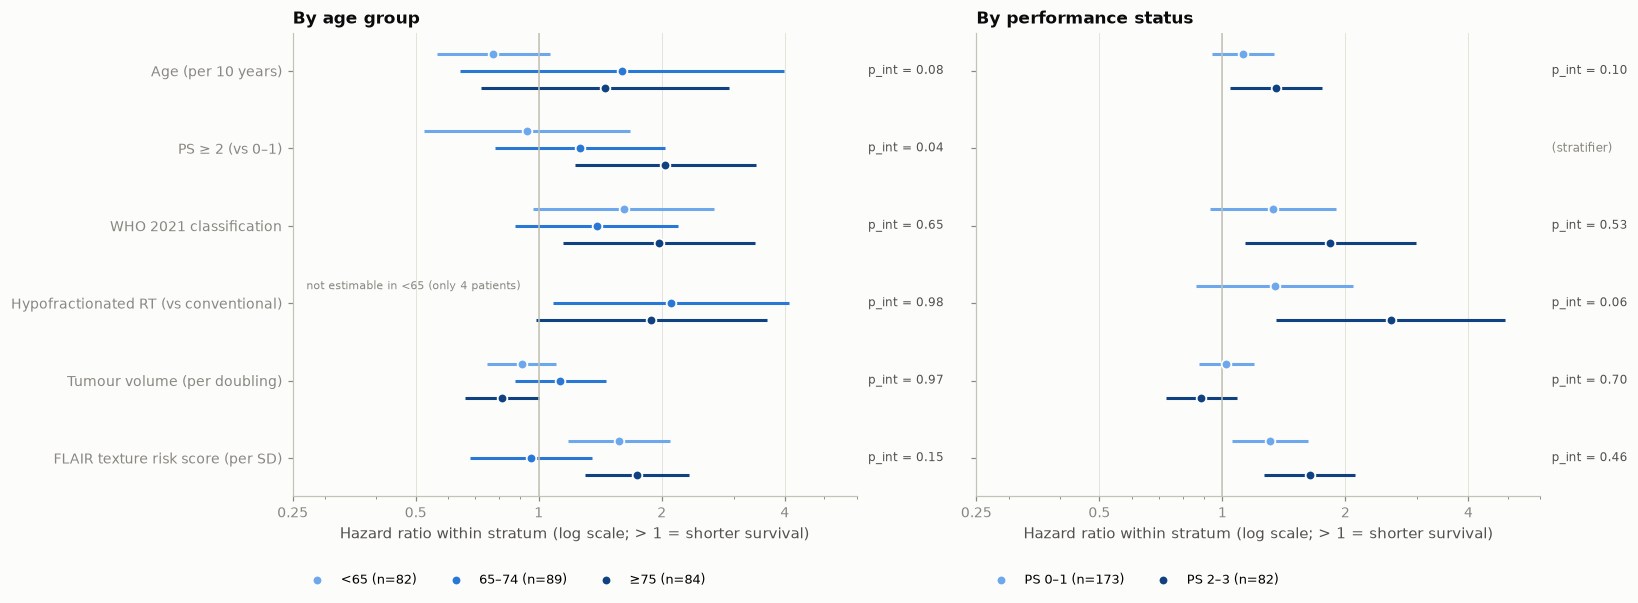

**Predictor importance within each stratum**: likelihood-ratio χ² for dropping the predictor (rank in brackets; higher = more important)

Stratifier                             Age group                         Performance status              
Stratum                               <65 (n=82) 65–74 (n=89) ≥75 (n=84)     PS 0–1 (n=173) PS 2–3 (n=82)
Predictor                                                                                                
Age (per 10 years)                      2.3 (#3)     1.0 (#3)   1.1 (#6)           1.8 (#3)      5.4 (#4)
PS ≥ 2 (vs 0–1)                         0.1 (#5)     0.9 (#5)   7.4 (#2)                  –             –
WHO 2021 classification                 3.2 (#2)     1.9 (#2)   5.6 (#3)           2.4 (#2)      5.9 (#3)
Hypofractionated RT (vs conventional)          –     4.3 (#1)   3.9 (#4)           1.7 (#4)      8.1 (#2)
Tumour volume (per doubling)            0.9 (#4)     0.9 (#4)   3.6 (#5)           0.1 (#5)      1.3 (#5)
FLAIR texture risk score (per SD)       9.5 (#1)     0.1 (#6)  14.1 (#1)           6.1 (#1)     14.0 (#1)

**Interaction tests**: does the predictor's effect differ across strata? (small p = yes)

Stratifier,Age group,Performance status
Predictor,,
Age (per 10 years),0.08,0.10
PS ≥ 2 (vs 0–1),0.04,(stratifier)
WHO 2021 classification,0.65,0.53
Hypofractionated RT (vs conventional),0.98,0.06
Tumour volume (per doubling),0.97,0.70
FLAIR texture risk score (per SD),0.15,0.46


In [26]:
sx = cvdat.copy()
sx["age_grp3"] = pd.cut(sx.age, [0, 64, 74, 120], labels=["<65", "65–74", "≥75"]).astype(str)
sx["ps_grp"] = np.where(sx.ps <= 1, "PS 0–1", "PS 2–3")
sx["ps_ge2"] = (sx.ps >= 2).astype(int)
sx["flair_z"] = (rad_score - rad_score.mean()) / rad_score.std()
display(Markdown("**Who is in each stratum** (treatment by age group)"))
display(pd.crosstab(sx.age_grp3, sx.regimen, margins=True).loc[["<65", "65–74", "≥75", "All"]])

PRED = {"age10": "Age (per 10 years)", "ps_ge2": "PS ≥ 2 (vs 0–1)", "who2021": "WHO 2021 classification",
        "hypo": "Hypofractionated RT (vs conventional)", "lv": "Tumour volume (per doubling)",
        "flair_z": "FLAIR texture risk score (per SD)"}
STRATA = {"Age group": ("age_grp3", ["<65", "65–74", "≥75"]), "Performance status": ("ps_grp", ["PS 0–1", "PS 2–3"])}

def sub_terms(strat_var):
    return [t for t in PRED if not (strat_var == "ps_grp" and t == "ps_ge2")] + ["unk"]

sub_rows, imp_rows = [], []
for sname, (svar, levels) in STRATA.items():
    terms = sub_terms(svar)
    for lev in levels:
        g = sx[sx[svar] == lev]
        full = CoxPHFitter(penalizer=1e-4).fit(g[["time", "event"] + terms], "time", "event")
        for t in terms[:-1]:
            s_ = full.summary.loc[t]
            estimable = not (t == "hypo" and min(g.hypo.sum(), (g.regimen == "Conventional").sum()) < 10)
            sub_rows.append({"Stratifier": sname, "Stratum": lev, "n": len(g), "Predictor": PRED[t],
                             "HR": s_["exp(coef)"] if estimable else np.nan,
                             "lo": s_["exp(coef) lower 95%"] if estimable else np.nan,
                             "hi": s_["exp(coef) upper 95%"] if estimable else np.nan, "p": s_["p"] if estimable else np.nan})
            red = CoxPHFitter(penalizer=1e-4).fit(g[["time", "event"] + [x for x in terms if x != t]], "time", "event")
            imp_rows.append({"Stratifier": sname, "Stratum": f"{lev} (n={len(g)})", "Predictor": PRED[t],
                             "chi2": 2 * (full.log_likelihood_ - red.log_likelihood_) if estimable else np.nan})
sub = pd.DataFrame(sub_rows)

# Interaction tests on the whole cohort: stratified Cox with vs without predictor × stratum terms
int_rows = []
for sname, (svar, levels) in STRATA.items():
    terms = sub_terms(svar)
    base_df = sx[["time", "event", svar] + terms].copy()
    null = CoxPHFitter(penalizer=1e-4).fit(base_df, "time", "event", strata=[svar])
    for t in terms[:-1]:
        df_i = base_df.copy()
        for lev in levels[1:]:
            df_i[f"{t}_x_{lev}"] = df_i[t] * (df_i[svar] == lev)
        alt = CoxPHFitter(penalizer=1e-4).fit(df_i, "time", "event", strata=[svar])
        lr_ = 2 * (alt.log_likelihood_ - null.log_likelihood_)
        int_rows.append({"Stratifier": sname, "Predictor": PRED[t], "LR χ²": lr_, "df": len(levels) - 1,
                         "p (interaction)": stats.chi2.sf(lr_, len(levels) - 1)})
ints = pd.DataFrame(int_rows)
ints.to_csv(OUT / "table11_interaction_tests.csv", index=False)
sub.to_csv(OUT / "table12_subgroup_hrs.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), sharey=True)
order = list(PRED.values())
for ax, (sname, (svar, levels)) in zip(axes, STRATA.items()):
    cols = ORD if len(levels) == 3 else [ORD[0], ORD[2]]
    offs = np.linspace(-0.22, 0.22, len(levels))
    for j, lev in enumerate(levels):
        a = sub[(sub.Stratifier == sname) & (sub.Stratum == lev)].set_index("Predictor").reindex(order)
        y = np.arange(len(order))[::-1] + offs[::-1][j]
        n_ = int(sub[(sub.Stratifier == sname) & (sub.Stratum == lev)].n.iloc[0])
        ax.hlines(y, a.lo, a.hi, color=cols[j], lw=2)
        ax.scatter(a.HR, y, color=cols[j], s=40, zorder=3, edgecolor=SURF, linewidth=1.2, label=f"{lev} (n={n_})")
    ip = ints[ints.Stratifier == sname].set_index("Predictor")["p (interaction)"]
    for i, pr in enumerate(order):
        if pr in ip.index:
            ax.text(1.02, len(order) - 1 - i, f"p_int = {ip[pr]:.2f}", transform=ax.get_yaxis_transform(),
                    fontsize=8, color=INK2, va="center")
        else:
            ax.text(1.02, len(order) - 1 - i, "(stratifier)", transform=ax.get_yaxis_transform(), fontsize=8, color=MUTED, va="center")
    ax.axvline(1, color=AXIS, lw=1); ax.set_xscale("log")
    ax.set_xlim(0.25, 6); ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(["0.25", "0.5", "1", "2", "4"])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("Hazard ratio within stratum (log scale; > 1 = shorter survival)")
    ax.set_title(f"By {sname.lower()}", loc="left"); ax.grid(axis="y", visible=False)
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.14), ncol=len(levels), fontsize=8.5)
axes[0].set_yticks(np.arange(len(order))[::-1]); axes[0].set_yticklabels(order)
axes[0].text(0.27, len(order) - 1 - order.index(PRED["hypo"]) + 0.22, "not estimable in <65 (only 4 patients)", fontsize=7.5, color=MUTED, va="center")
fig.tight_layout(); savefig(fig, "fig10_subgroup_forest"); plt.show()

imp_tab = pd.DataFrame(imp_rows).pivot_table(index="Predictor", columns=["Stratifier", "Stratum"], values="chi2", sort=False)
imp_rank = imp_tab.rank(ascending=False, method="min")
imp_show = imp_tab.round(1).astype(str).where(imp_tab.notna(), "–") + " (#" + imp_rank.fillna(0).astype(int).astype(str) + ")"
imp_show = imp_show.where(imp_tab.notna(), "–").reindex(order)
display(Markdown("**Predictor importance within each stratum**: likelihood-ratio χ² for dropping the predictor (rank in brackets; higher = more important)"))
display(imp_show)
display(Markdown("**Interaction tests**: does the predictor's effect differ across strata? (small p = yes)"))
display(ints.pivot(index="Predictor", columns="Stratifier", values="p (interaction)").reindex(order)
        .style.format("{:.2f}", na_rep="(stratifier)"))

### 8.1 Would a stratified prediction model predict better?

In [27]:
cvdat["age_grp3"] = sx["age_grp3"]; cvdat["ps_grp"] = sx["ps_grp"]

class StratCoxModel(CoxModel):
    """Cox model with a separate baseline survival curve per stratum; predictor effects shared."""
    def __init__(self, design, stratum, flair_pcs=0, drop=()):
        super().__init__(design, flair_pcs); self.stratum, self.drop = stratum, list(drop)
    def _Xs(self, d, fit=False):
        X = self._X(d, fit).drop(columns=self.drop)
        X["_s"] = d[self.stratum].values
        return X
    def fit(self, d):
        self.cph = CoxPHFitter(penalizer=1e-4).fit(self._Xs(d, fit=True).assign(time=d.time, event=d.event),
                                                   "time", "event", strata=["_s"])
        return self
    def survival(self, d):
        X = self._Xs(d)
        sf = self.cph.predict_survival_function(X, times=GRID)   # lifelines returns columns grouped by stratum...
        return sf[X.index].T.values                              # ...so restore the input patient order

class SeparateModels:
    """A separate (linear-term) clinical Cox model within each stratum."""
    def __init__(self, stratum): self.stratum = stratum
    def fit(self, d):
        self.models, self.cols = {}, {}
        for lev, g in d.groupby(self.stratum):
            X = ClinicalDesign(volume=True, spline=False).fit(g).transform(g)
            X = X.loc[:, X.std() > 0]
            self.cols[lev] = X.columns
            self.models[lev] = CoxPHFitter(penalizer=0.01).fit(X.assign(time=g.time, event=g.event), "time", "event")
        return self
    def survival(self, d):
        S = np.zeros((len(d), len(GRID)))
        for lev, g in d.groupby(self.stratum):
            X = ClinicalDesign(volume=True, spline=False).fit(g).transform(g)[self.cols[lev]]
            S[np.where(d[self.stratum].values == lev)[0]] = self.models[lev].predict_survival_function(X, times=GRID).T.values
        return S

STRAT_MODELS = {
    "Model B, stratified by age group":      lambda: StratCoxModel(ClinicalDesign(True, True), "age_grp3"),
    "Model B, stratified by PS group":       lambda: StratCoxModel(ClinicalDesign(True, True), "ps_grp", drop=["ps2"]),
    "Model C, stratified by age group":      lambda: StratCoxModel(ClinicalDesign(True, True), "age_grp3", flair_pcs=5),
    "Model C, stratified by PS group":       lambda: StratCoxModel(ClinicalDesign(True, True), "ps_grp", flair_pcs=5, drop=["ps2"]),
    "Separate clinical models per age group": lambda: SeparateModels("age_grp3"),
    "Separate clinical models per PS group":  lambda: SeparateModels("ps_grp"),
}

def run_strat_fold(r, k, tr, te):
    TR, TE = cvdat.iloc[tr], cvdat.iloc[te]
    return [{"rep": r, "fold": k, "model": name, **metrics(TE.time.values, make().fit(TR).survival(TE))}
            for name, make in STRAT_MODELS.items()]

cache_s = OUT / "cv_results_stratified.csv"
if cache_s.exists():
    cvs = pd.read_csv(cache_s)
else:
    tasks = [(r, k, tr, te) for r in range(N_REPEATS)
             for k, (tr, te) in enumerate(KFold(5, shuffle=True, random_state=SEED + r).split(cvdat))]
    cvs = pd.DataFrame([row for rows in Parallel(n_jobs=-1)(delayed(run_strat_fold)(*t) for t in tasks) for row in rows])
    cvs.to_csv(cache_s, index=False)

allcv = pd.concat([cvres[cvres.model.isin([BEDSIDE_NAME, FINAL_NAME])], cvs])
pv_ = allcv.pivot_table(index=["rep", "fold"], columns="model", values="C-index")
st_perf = allcv.groupby("model")[["C-index", "AUC 26 wk", "AUC 52 wk", "AUC 104 wk", "Integrated Brier"]].mean()
st_perf["ΔC vs Model B"] = pv_.sub(pv_[BEDSIDE_NAME], axis=0).mean()
st_perf["ΔC vs Model C"] = pv_.sub(pv_[FINAL_NAME], axis=0).mean()
st_perf["% splits better than C"] = pv_.gt(pv_[FINAL_NAME], axis=0).mean() * 100
st_perf = st_perf.loc[[BEDSIDE_NAME, FINAL_NAME] + list(STRAT_MODELS)]
st_perf.to_csv(OUT / "table13_cv_stratified.csv")
display(Markdown("**Cross-validated performance of stratified models** (same 50 splits as §5.2)"))
display(st_perf.style.format("{:.3f}").format({"ΔC vs Model B": "{:+.3f}", "ΔC vs Model C": "{:+.3f}", "% splits better than C": "{:.0f}%"}))

**Cross-validated performance of stratified models** (same 50 splits as §5.2)

,C-index,AUC 26 wk,AUC 52 wk,AUC 104 wk,Integrated Brier,ΔC vs Model B,ΔC vs Model C,% splits better than C
model,,,,,,,,
"Clinical + volume, splines (Cox) [Model B]",0.627877,0.725604,0.713194,0.631896,0.170696,+0.000,-0.010,36%
Model B + 5 FLAIR principal components (Cox),0.638126,0.739757,0.713115,0.665228,0.169161,+0.010,+0.000,0%
"Model B, stratified by age group",0.636404,0.733158,0.715418,0.654019,0.170279,+0.009,-0.002,48%
"Model B, stratified by PS group",0.629158,0.733329,0.712239,0.633423,0.169902,+0.001,-0.009,32%
"Model C, stratified by age group",0.645055,0.747156,0.720326,0.681793,0.168805,+0.017,+0.007,76%
"Model C, stratified by PS group",0.640137,0.745920,0.714808,0.667742,0.168573,+0.012,+0.002,60%
Separate clinical models per age group,0.603485,0.695943,0.666913,0.605643,0.181932,-0.024,-0.035,16%
Separate clinical models per PS group,0.615405,0.710798,0.682243,0.629151,0.174511,-0.012,-0.023,22%


**How well does the final model rank patients *within* each subgroup?** This is the out-of-fold C-index of Model C computed inside each stratum.
It is naturally lower than overall, because patients within a stratum are more alike, but it shows whether the model is still useful for, say, choosing among elderly patients.

In [28]:
o_c = oof_avg[FINAL_NAME].join(sx[["age_grp3", "ps_grp"]])
within = []
for svar, lab in [("age_grp3", "Age group"), ("ps_grp", "Performance status")]:
    for lev, g in o_c.groupby(svar):
        c_ = concordance_index_censored(np.ones(len(g), bool), g.time.astype(float).values, -g.S52.values)[0]
        within.append({"Stratifier": lab, "Stratum": lev, "n": len(g), "Within-stratum C-index (Model C)": c_,
                       "Median survival, wk": g.time.median()})
display(pd.DataFrame(within).set_index(["Stratifier", "Stratum"]).style.format({"Within-stratum C-index (Model C)": "{:.3f}", "Median survival, wk": "{:.0f}"}))

### 8.2 What the stratified analyses show
**The best predictors are largely the same in every subgroup.**
* The **FLAIR texture risk score** is the most important predictor in 4 of the 5 subgroups (young, old, fit and less fit patients). The exception is age 65–74, where its effect is close to null. The interaction test does not show this difference to be reliable (p = 0.15).
* **WHO 2021 classification** ranks 2nd–3rd almost everywhere, with no evidence of differing effects (interaction p = 0.53–0.65).
* **Tumour volume** and **age** matter less once patients are compared within a narrower group, and their effects are consistent across groups.

**Two signals that may differ by subgroup** (hypothesis-generating: about 11 interaction tests were run, so one p ≈ 0.04 could be chance):
* **Performance status matters in the elderly, not in younger patients.** PS ≥ 2 roughly doubles the death rate in patients ≥ 75, but shows no effect in patients < 65 (interaction p = 0.04). This is clinically plausible: older patients with poor function have less reserve to tolerate treatment.
* **Hypofractionated RT carries a worse prognosis mainly in less-fit (PS 2–3) patients** (HR ≈ 2.6 vs ≈ 1.4 in PS 0–1; interaction p = 0.06). As elsewhere, this reflects who receives the short course, not harm from it.

**Prediction: share the effects, let the baseline differ.**
* **Separate models per subgroup predict worse** (C 0.60–0.62 vs 0.64). With ~85 patients per model, the extra freedom costs more in over-fitting than it gains.
* **A Cox model stratified by age group** (its own baseline survival curve per age band, shared predictor effects) improves Model C slightly: **C 0.645 vs 0.638**, 2-year AUC 0.68 vs 0.67. It was better in 76% of splits and in 9 of 10 repeats. This suggests the *shape* of the survival curve over time differs by age, not just its level. Stratifying by PS gives no gain.
* **Recommendation:** keep Model C as the primary model and report the age-stratified version as a promising variant. The gain is small and was found after comparing many models, so it needs confirmation in external data. The age-stratified model also has a practical drawback: predictions jump at the age-band boundaries (a 74-year-old and a 75-year-old get different baseline curves). A smooth age × time interaction would avoid that.
* Within subgroups, Model C still ranks patients modestly well. It discriminates best among patients ≥ 75 (C 0.65) and least among patients < 75 (C ≈ 0.58). Predicting survival among younger, fitter patients is the hardest case, which is where molecular markers such as MGMT and IDH would help most.

## 9. Limitations
1. **Single centre, n = 264, no external validation.** Cross-validation estimates performance in *similar* patients. The model needs validation in an independent cohort, ideally from another institution with different MRI scanners, before any clinical use.
2. **Key molecular and surgical prognostic factors are missing**: MGMT promoter methylation, IDH status, extent of resection, and concurrent/adjuvant temozolomide. These are among the strongest known predictors in glioblastoma, so they explain much of the remaining unexplained variation (C ≈ 0.64).
3. **Treatment variables are not randomized.** The HRs for RT regimen and delay are *prognostic* (they reflect clinicians' judgement of frailty), not causal estimates of treatment benefit.
4. **WHO edition is a proxy.** "WHO 2021" probably flags tumours classified under the IDH-wildtype-only definition, and possibly a later calendar period. New patients will all be classified under 2021, so predictions should use `who2021=1`.
5. **Proportional hazards is only approximately met.** Frailty markers (PS 2, hypofractionated RT) act mainly in the first 6 months. A time-varying model fits slightly better (lower Brier score) but does not improve discrimination, so the simpler PH model was kept.
6. **2-year predictions for the best-prognosis patients are optimistic** (§5.4), and calibration slopes < 1 indicate mild over-fitting. Shrinking the coefficients, or re-calibrating on external data, would be a sensible next step.
7. **Radiomics reproducibility**: features depend on the scanner, preprocessing and segmentation. The FLAIR components must be computed with exactly the same pipeline (PyRadiomics settings, intensity standardization, GTV mask) for Model C to apply.

## 10. Reproducibility
Python environment: pandas, numpy, scipy, lifelines, scikit-survival, scikit-learn, statsmodels, matplotlib (see `requirements.txt`). Cross-validation results are cached in `outputs/cv_results.csv`; delete that file to recompute (~3 min on 8 cores). All figures and tables are written to `outputs/`.